# 🏋️ G14 · วิเคราะห์ความเสี่ยงการยกแบบครบวงจร (มุมบิด + ระยะเอื้อม + นับรอบยก)

**รายวิชา CP413705 การฝึกปฏิบัติงานปัญญาประดิษฐ์ 3 (AI Workshop III)** · กลุ่ม G14

Notebook นี้รวมงานสามส่วนที่เคยแยกกันให้อยู่ในลูปเดียว ทำงานทีละเฟรมแบบที่ระบบจริงต้องทำ

| ส่วน | มาจาก | ได้อะไร |
|---|---|---|
| โมเดลเชิงเรขาคณิต | `Workshop_LiftingWeightLimit_Realtime_Colab` ของอาจารย์ | มุมหันเทียบกล้อง · **มุมบิดตัว** · **ระยะเอื้อม H / ความสูงมือ V** · ตารางน้ำหนักสูงสุด 3×4 |
| โมเดลที่เราเทรนเอง | `G14_Workshop12` (Transformer, 166 features, window 60) | กิจกรรมรายเฟรม 5 คลาส → **นับรอบการยก** |
| รายงานผล | ส่วนที่เขียนเพิ่มใน notebook นี้ | ตารางสรุป **รายรอบการยก** + ท่าที่แย่ที่สุดของแต่ละรอบ |

```
 วิดีโอ ─► ① อ่านเฟรม ─► ② keypoint ─► ③ ลดการสั่น ─┬─► ⑤ สเกล + พิกัด 3 มิติ ─► ⑥ มุมหัน ─► ⑦ มุมบิด ─► ⑧ H/V + ตารางน้ำหนัก ─┐
                                                   │                                                                      ├─► ⑪ วิดีโอ + CSV + สรุปรายรอบ
                                                   └─► ⑨ features 166 ค่า ─► Transformer (60 เฟรม) ─► ⑩ LIFT/NO LIFT + นับรอบ ─┘
```

### สิ่งที่ต้องเตรียม
| รายการ | หมายเหตุ |
|---|---|
| วิดีโอการยก `.mp4` | กล้องตั้งนิ่ง · ผู้ยก **ยืนตรงนิ่ง 2 วินาทีแรก** (ใช้ calibrate) |
| ส่วนสูงจริงของผู้ยก (ซม.) | กรอกในขั้นที่ 0.2 — มีผลโดยตรงกับค่า H/V เป็นเซนติเมตร |
| โฟลเดอร์โมเดล Workshop12 | `best_model.pt` · `features.csv` · `class_map.csv` · `scaler.csv` · `settings.csv` |
| `pose_landmarker_lite.task` | ดาวน์โหลดอัตโนมัติถ้าไม่มี |

> ⚠️ ต้องใช้ **OpenCV 4.x** — บน OpenCV 5 ฟังก์ชัน `cv2.putText` ไม่รับภาพ float32 แล้ว ตอนวาดตารางจะ error
> (Colab ใช้ 4.14 จึงไม่มีปัญหา ถ้ารันบนเครื่องตัวเองให้ `pip install "opencv-contrib-python<5"`)

---
## ขั้นที่ 0 · เตรียมสภาพแวดล้อม

### 0.1 ติดตั้งและนำเข้าไลบรารี

In [1]:
import subprocess, sys

for module, package in [("mediapipe", "mediapipe"), ("torch", "torch")]:
    try:
        __import__(module)
    except ImportError:
        print(f"กำลังติดตั้ง {package} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import math, re, time, shutil, base64, urllib.request, warnings
from pathlib import Path
from collections import deque, Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mediapipe as mp
import torch
from torch import nn
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision
from IPython.display import HTML, display

warnings.filterwarnings("ignore", category=RuntimeWarning)
print("OpenCV", cv2.__version__, "| MediaPipe", mp.__version__, "| PyTorch", torch.__version__)
if int(cv2.__version__.split(".")[0]) >= 5:
    print("⚠️ OpenCV 5 ขึ้นไปจะ error ตอนวาดตาราง — ให้ลดเป็น 4.x")

OpenCV 4.14.0 | MediaPipe 1.1.0 | PyTorch 2.14.0+cpu


### 0.2 ตั้งค่า 👉 MODIFY
- **บน Colab** วางไฟล์ไว้ที่ `/content/lift_demo` (อัปโหลดในขั้น 0.3) · **บนเครื่องตัวเอง** ใช้โฟลเดอร์ที่ notebook วางอยู่
- `SUBJECT_HEIGHT_CM` คือส่วนสูงจริงของผู้ยกในคลิป ค่านี้กำหนดสเกลเป็นเซนติเมตรของทั้งระบบ
- ค่าพารามิเตอร์ของกลุ่มอยู่ในขั้นที่ ⑤ (ตั้งจากการทดลองในหัวข้อ "ปรับค่าตั้งต้น" ท้าย notebook)

In [2]:
IN_COLAB = "google.colab" in sys.modules
BASE = Path("/content/lift_demo") if IN_COLAB else Path.cwd()   # 👉 MODIFY — โฟลเดอร์ทำงาน
BASE.mkdir(parents=True, exist_ok=True)

VIDEO_NAME        = "VID_long.mp4"   # 👉 MODIFY — ชื่อไฟล์วิดีโอ
SUBJECT_HEIGHT_CM = 167.0                             # 👉 MODIFY — ส่วนสูงจริงของผู้ยก (ซม.)
MAX_FRAMES        = None                              # 👉 MODIFY — เช่น 150 เพื่อทดลองเร็ว ๆ · None = ทั้งคลิป
MODEL_DIR         = BASE / "model"                    # 👉 MODIFY — โฟลเดอร์โมเดล Workshop12 ของกลุ่ม
CKPT_NAME         = "best_model.pt"

VIDEO_PATH      = BASE / VIDEO_NAME
POSE_MODEL_PATH = BASE / "models" / "pose_landmarker_lite.task"
OUTPUT_DIR      = BASE / "liftrisk_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_FILES = [CKPT_NAME, "features.csv", "class_map.csv", "scaler.csv", "settings.csv"]

### 0.3 เตรียมไฟล์
โมเดล MediaPipe ดาวน์โหลดอัตโนมัติ · บน Colab จะขึ้นปุ่มให้อัปโหลดวิดีโอและไฟล์โมเดลที่ยังไม่มี

In [3]:
POSE_MODEL_URL = ("https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
                  "pose_landmarker_lite/float16/latest/pose_landmarker_lite.task")

if not POSE_MODEL_PATH.is_file():
    POSE_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    print("กำลังดาวน์โหลดโมเดล MediaPipe ...")
    urllib.request.urlretrieve(POSE_MODEL_URL, POSE_MODEL_PATH)


def upload_into(folder, what):
    from google.colab import files
    folder.mkdir(parents=True, exist_ok=True)
    print(f"📤 เลือกไฟล์ {what}")
    for name, data in files.upload().items():
        (folder / name).write_bytes(data)


missing_model = [f for f in MODEL_FILES if not (MODEL_DIR / f).is_file()]
if IN_COLAB and not VIDEO_PATH.is_file():
    upload_into(BASE, f"วิดีโอ ({VIDEO_NAME})")
if IN_COLAB and missing_model:
    upload_into(MODEL_DIR, "โมเดล Workshop12: " + ", ".join(missing_model))

for p in [VIDEO_PATH, POSE_MODEL_PATH] + [MODEL_DIR / f for f in MODEL_FILES]:
    print("✅" if p.is_file() else "❌ ไม่พบ", p)
assert VIDEO_PATH.is_file(), "ไม่พบวิดีโอ — แก้ VIDEO_NAME ในขั้น 0.2"
assert all((MODEL_DIR / f).is_file() for f in MODEL_FILES), "ไฟล์โมเดลยังไม่ครบ"

✅ C:\Users\usEr\AppData\Local\Temp\claude\C--Users-usEr-Desktop-Working-2026-College-Project-AIW3-AIW3---------\e9f1c371-22a7-41ef-b356-309d818ac8f6\scratchpad\work\VID_long.mp4
✅ C:\Users\usEr\AppData\Local\Temp\claude\C--Users-usEr-Desktop-Working-2026-College-Project-AIW3-AIW3---------\e9f1c371-22a7-41ef-b356-309d818ac8f6\scratchpad\work\models\pose_landmarker_lite.task
✅ C:\Users\usEr\AppData\Local\Temp\claude\C--Users-usEr-Desktop-Working-2026-College-Project-AIW3-AIW3---------\e9f1c371-22a7-41ef-b356-309d818ac8f6\scratchpad\work\model\best_model.pt
✅ C:\Users\usEr\AppData\Local\Temp\claude\C--Users-usEr-Desktop-Working-2026-College-Project-AIW3-AIW3---------\e9f1c371-22a7-41ef-b356-309d818ac8f6\scratchpad\work\model\features.csv
✅ C:\Users\usEr\AppData\Local\Temp\claude\C--Users-usEr-Desktop-Working-2026-College-Project-AIW3-AIW3---------\e9f1c371-22a7-41ef-b356-309d818ac8f6\scratchpad\work\model\class_map.csv
✅ C:\Users\usEr\AppData\Local\Temp\claude\C--Users-usEr-Desktop-Workin

---
## ขั้นที่ ① · อ่านและโหลดเฟรมภาพจากไฟล์วิดีโอ

วิดีโอคือ **ภาพนิ่ง (เฟรม) หลายภาพเรียงต่อกัน** — ชุดข้อมูลของเราบันทึกที่ 30 เฟรมต่อวินาที
- `cv2.VideoCapture(path)` เปิดวิดีโอ แล้ว `cap.read()` คืน `(ok, frame)` ทีละเฟรม (`ok = False` เมื่อวิดีโอหมด)
- `frame` เป็น NumPy array ขนาด `(สูง, กว้าง, 3)` เรียงสีแบบ **BGR** (ไม่ใช่ RGB)

In [4]:
def open_video(path):
    # เปิดวิดีโอ คืน (cap, ข้อมูลวิดีโอ)
    cap = cv2.VideoCapture(str(path))
    info = {
        "fps": cap.get(cv2.CAP_PROP_FPS),
        "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
        "frames": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
    }
    return cap, info


def read_frame(path, frame_number):
    # อ่านเฟรมที่ต้องการ (นับจาก 1)
    cap, _ = open_video(path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number - 1)
    ok, frame = cap.read()
    cap.release()
    return frame


def show_images(images, titles, width=4):
    # แสดงภาพ BGR หลายภาพเรียงกัน
    fig, axes = plt.subplots(1, len(images), figsize=(width * len(images), width * 1.6))
    axes = np.atleast_1d(axes)
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))     # BGR → RGB ก่อนแสดง
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

cap, VIDEO_INFO = open_video(VIDEO_PATH)
cap.release()
FPS, WIDTH, HEIGHT = VIDEO_INFO["fps"], VIDEO_INFO["width"], VIDEO_INFO["height"]
print(VIDEO_INFO, f"→ ยาว {VIDEO_INFO['frames'] / FPS:.1f} วินาที")

{'fps': 30.0, 'width': 1080, 'height': 1920, 'frames': 2023}

 → ยาว 67.4 วินาที


---
## ขั้นที่ ② · สกัดจุดพิกัดร่างกาย (Keypoints Extraction) ด้วย Function Call

**MediaPipe Pose Landmarker** คืน **33 จุด** ของร่างกาย 2 แบบ

| ผลลัพธ์ | ค่า | ความหมาย |
|---|---|---|
| `pose_landmarks` | `x`, `y` (0–1) | ตำแหน่งในภาพ → คูณด้วยขนาดภาพได้ **พิกเซล** |
| | `visibility`, `presence` | ความมั่นใจ → ใช้ `confidence = min(visibility, presence)` |
| `pose_world_landmarks` | `x`, `y`, `z` | **โครงร่าง 3 มิติ หน่วยเมตร** จุดกำเนิดที่กึ่งกลางสะโพก |

จุดที่ใช้บ่อย: `0` จมูก · `11/12` ไหล่ · `15/16` ข้อมือ · `17–20` นิ้วก้อย/นิ้วชี้ · `23/24` สะโพก · `25/26` เข่า · `27/28` ข้อเท้า · `29/30` ส้นเท้า · `31/32` ปลายเท้า

> ⚠️ ใช้โหมด `VIDEO` ซึ่งต้องส่ง **timestamp (มิลลิวินาที) ที่เพิ่มขึ้นทุกเฟรม** → ใช้ `เลขเฟรม × 1000 / fps`

In [5]:
def create_pose_detector():
    # สร้างตัวตรวจจับท่าทาง (สร้างครั้งเดียว ใช้ได้ทั้งคลิป)
    options = mp_vision.PoseLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=str(POSE_MODEL_PATH)),
        running_mode=mp_vision.RunningMode.VIDEO,
        num_poses=1)
    return mp_vision.PoseLandmarker.create_from_options(options)


def extract_keypoints(detector, frame, frame_index):
    # ② คืน xy (33, 2) พิกเซล · world (33, 3) เมตร · conf (33,)   (เป็น NaN ถ้าไม่พบคน)
    h, w = frame.shape[:2]
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    timestamp_ms = int(frame_index * 1000 / FPS)
    result = detector.detect_for_video(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb), timestamp_ms)

    xy = np.full((33, 2), np.nan)
    world = np.full((33, 3), np.nan)
    conf = np.full(33, np.nan)
    if result.pose_landmarks:
        for i, lm in enumerate(result.pose_landmarks[0]):
            xy[i] = [lm.x * w, lm.y * h]
            conf[i] = min(lm.visibility, lm.presence)
        for i, lm in enumerate(result.pose_world_landmarks[0]):
            world[i] = [lm.x, lm.y, lm.z]
    return xy, world, conf

---
## ขั้นที่ ③ · การติดตามและลดการสั่นไหวของพิกัด (Tracking and Smoothing)

keypoint ดิบ **สั่น** ทุกเฟรม บางเฟรมกระโดดผิดที่หรือหายไป เราจึงกรองแต่ละจุดด้วย

**(ก) Kalman filter** — จำตำแหน่งและความเร็วของจุด ทุกเฟรมทำ 2 อย่าง
1. **predict** ทายตำแหน่งเฟรมนี้จากตำแหน่ง + ความเร็วเดิม
2. **correct** ถ้าค่าที่วัดได้ "ดี" (confidence ≥ 0.5 · อยู่ในภาพ · ไม่กระโดดไกลเกิน `gate`) ให้ปรับค่าทายเข้าหาค่าวัด
   ถ้าไม่ดี ใช้ค่าทายแทนได้ไม่เกิน `MAX_PREDICT_FRAMES` เฟรม

**(ข) Moving average ย้อนหลัง** — เฉลี่ยตำแหน่งเฟรมนี้กับ `HISTORY_FRAMES` เฟรมก่อนหน้า (ใช้แต่อดีต เหมาะกับ real-time)

**(ค) โครงร่าง 3 มิติ** เฉลี่ยย้อนหลัง `WORLD_WINDOW` เฟรม

In [6]:
MIN_CONFIDENCE     = 0.5   # ค่าวัดที่ confidence ต่ำกว่านี้ไม่ใช้
MAX_PREDICT_FRAMES = 5     # ใช้ค่าทายแทนได้ติดกันกี่เฟรม
HISTORY_FRAMES     = 3     # moving average = เฟรมนี้ + 3 เฟรมก่อนหน้า
WORLD_WINDOW       = 5     # 👉 MODIFY — จำนวนเฟรมที่เฉลี่ยโครงร่าง 3 มิติ


def create_kalman(x, y):
    # Kalman filter แบบความเร็วคงที่  สถานะ = [x, y, vx, vy]  ค่าวัด = [x, y]
    kf = cv2.KalmanFilter(4, 2)
    kf.transitionMatrix = np.array([[1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 1, 0], [0, 0, 0, 1]], np.float32)
    kf.measurementMatrix = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], np.float32)
    acc = np.array([[0.5, 0], [0, 0.5], [1, 0], [0, 1]], np.float32)
    kf.processNoiseCov = 16.0 * acc @ acc.T                     # การเคลื่อนที่ไม่แน่นอนแค่ไหน
    kf.measurementNoiseCov = np.eye(2, dtype=np.float32) * 25.0  # ค่าวัดคลาดเคลื่อนประมาณ 5 px
    kf.errorCovPost = np.diag([25, 25, 400, 400]).astype(np.float32)
    kf.statePost = np.array([[x], [y], [0], [0]], np.float32)
    return kf


class PointTracker:
    # ติดตาม + ลดการสั่นของ keypoint 1 จุด

    def __init__(self, width, height):
        self.width, self.height = width, height
        self.gate = max(25.0, 0.04 * math.hypot(width, height))   # ระยะกระโดดสูงสุดที่ยอมรับ (px)
        self.kalman = None       # None = ยังไม่ได้เริ่มติดตาม
        self.missing = 0         # จำนวนเฟรมติดกันที่ไม่มีค่าวัดที่ดี
        self.history = []        # ตำแหน่งล่าสุด สำหรับ moving average

    def update(self, x, y, conf):
        # คืน (ตำแหน่งที่กรองแล้ว, วัดได้จริงในเฟรมนี้หรือไม่)
        good = conf >= MIN_CONFIDENCE and 0 <= x < self.width and 0 <= y < self.height   # NaN → False
        point, observed = None, False

        if self.kalman is None:                          # ยังไม่ได้ติดตาม → เริ่มเมื่อค่าวัดดี
            if good:
                self.kalman = create_kalman(x, y)
                point, observed = np.array([x, y]), True
        else:
            predicted = self.kalman.predict()[:2, 0]     # (ก-1) predict
            jump = math.hypot(x - predicted[0], y - predicted[1]) if good else 0
            if good and jump <= self.gate:               # (ก-2) correct ด้วยค่าวัด
                self.kalman.correct(np.array([[x], [y]], np.float32))
                point, observed = np.array([x, y]), True
                self.missing = 0
            else:                                        # ไม่มีค่าวัดที่ดี → ใช้ค่าทาย
                self.missing += 1
                inside = 0 <= predicted[0] < self.width and 0 <= predicted[1] < self.height
                if self.missing <= MAX_PREDICT_FRAMES and inside:
                    point = predicted
                else:                                    # หายนานเกินไป → เริ่มใหม่
                    self.kalman, self.missing, self.history = None, 0, []

        if point is None:
            return np.array([np.nan, np.nan]), False
        self.history = (self.history + [point])[-(HISTORY_FRAMES + 1):]   # (ข) moving average
        return np.mean(self.history, axis=0), observed


class PoseSmoother:
    # PointTracker 33 ตัว (สำหรับภาพ) + ค่าเฉลี่ยย้อนหลังของโครงร่าง 3 มิติ

    def __init__(self, width, height):
        self.trackers = [PointTracker(width, height) for _ in range(33)]
        self.world_history = deque(maxlen=WORLD_WINDOW)

    def update(self, xy, world, conf):
        xy_s = np.full((33, 2), np.nan)
        observed = np.zeros(33, dtype=bool)
        for i in range(33):
            xy_s[i], observed[i] = self.trackers[i].update(xy[i, 0], xy[i, 1], conf[i])
        self.world_history.append(world)
        world_s = np.nanmean(np.array(self.world_history), axis=0)    # (ค)
        return xy_s, world_s, observed

---
## ขั้นที่ ④ · การวาดจุด Keypoints ลงบนเฟรมภาพ

วาดเส้นโครงกระดูกด้วย `cv2.line` และจุดด้วย `cv2.circle` — จุด **เขียว** = วัดได้จริง · **ส้ม** = ค่าที่ Kalman ทายแทน
(OpenCV ใช้สีแบบ **(B, G, R)**)

In [7]:
SKELETON = [(11, 12), (11, 23), (12, 24), (23, 24),                  # ลำตัว
            (11, 13), (13, 15), (15, 17), (15, 19),                  # แขนซ้าย
            (12, 14), (14, 16), (16, 18), (16, 20),                  # แขนขวา
            (23, 25), (25, 27), (27, 29), (27, 31), (29, 31),        # ขาซ้าย
            (24, 26), (26, 28), (28, 30), (28, 32), (30, 32),        # ขาขวา
            (0, 11), (0, 12)]                                        # ศีรษะ


def pt(p):
    # แปลงพิกัดทศนิยมเป็นจุดจำนวนเต็มสำหรับ OpenCV
    return (int(round(p[0])), int(round(p[1])))


def ui_scale(img):
    # ขนาดตัวอักษร/เส้น เทียบกับภาพกว้าง 720 px
    return img.shape[1] / 720


def draw_skeleton(img, xy_s, observed):
    # ④ วาดโครงกระดูกลงบนภาพ
    s = ui_scale(img)
    for a, b in SKELETON:
        if np.isfinite(xy_s[a]).all() and np.isfinite(xy_s[b]).all():
            cv2.line(img, pt(xy_s[a]), pt(xy_s[b]), (255, 255, 255), max(1, int(2 * s)), cv2.LINE_AA)
    for a, b in SKELETON:
        for p in (a, b):
            if np.isfinite(xy_s[p]).all():
                color = (0, 200, 0) if observed[p] else (0, 140, 255)
                cv2.circle(img, pt(xy_s[p]), max(2, int(4 * s)), color, -1, cv2.LINE_AA)
    return img

---
## ขั้นที่ ⑤ · การคำนวณมาตราส่วนเทียบเคียง (cm/pixel Ratio) และพิกัด 3 มิติ

ใช้ **ช่วงยืนตรงนิ่งต้นคลิป** (`CALIB_SECONDS` วินาที) กับ **ส่วนสูงจริง** สร้างเครื่องมือวัด ทำครั้งเดียวแล้วใช้ทั้งคลิป

### 5.1 สเกลในภาพ: ซม./พิกเซล
$$
\text{cm/px} = \frac{\text{ส่วนสูงจริง} \times 0.905}{\operatorname{median}(y_{\text{floor}} - y_{\text{nose}})}
$$
- $y_{\text{floor}}$ = ระดับพื้น = y ที่ต่ำที่สุดของส้นเท้า/ปลายเท้า · **0.905** = ระยะพื้นถึงจมูกเป็นสัดส่วนของส่วนสูง
- ระยะกล้องถึงผู้ยก $D = f \times \text{cm/px}$ โดย $f$ = ความยาวโฟกัส (พิกเซล) จากมุมมองกล้อง `CAMERA_FOV_DEG`

### 5.2 พิกัด 3 มิติของทุกจุด (หน่วย ซม.)
1. ขยายโครงร่าง 3 มิติของ MediaPipe (`world`) ให้สูงเท่าผู้ยกจริง → `world_scale`
2. **`cv2.solvePnP`** หาว่ากล้องมองโครงร่างนั้นจากมุมไหน (การหมุน $R$ และเลื่อน $t$) → ได้ **ความลึก $Z$** ของแต่ละจุด
3. รวมกับตำแหน่ง $(u, v)$ ในภาพ ด้วยสูตรกล้องรูเข็ม: $X = (u - c_x)Z/f$ · $Y = (v - c_y)Z/f$

### 5.3 กรอบพิกัดของร่างกาย
```
     มองจากด้านบน                              มองจากด้านข้าง
   hipL ●━━━━━━━━━━━━━● hipR  ← ระนาบสะโพก         │ up (แนวดิ่ง)
                 ┃ front                            │     ● กึ่งกลางมือ
                 ▼ (ตั้งฉากกับระนาบสะโพก)            │     ┆ V = ความสูงจากพื้น
                                             O ●────┘
                                    (กึ่งกลางข้อเท้า)   H = ระยะแนวราบ O → มือ
```
| ทิศ | ความหมาย |
|---|---|
| `up` | แนวดิ่ง = ทิศจากเท้าไปสะโพก **ขณะยืนตรง** (กล้องตั้งนิ่ง จึงคงที่ทั้งคลิป) |
| `side` | เส้นสะโพก ซ้าย→ขวา (ตัดส่วนที่เป็นแนวดิ่งออก) |
| `front` | ตั้งฉากกับทั้งสองทิศข้างบน = **ตั้งฉากกับระนาบสะโพก** หันไปทางปลายเท้า |
| `O` | **กึ่งกลางข้อเท้าทั้งสอง ที่ระดับพื้น** (จุดอ้างอิงของ NIOSH) — ระดับพื้นวัดครั้งเดียวตอนยืนนิ่ง |

ช่วงยืนนิ่งยังใช้วัด **ความสูงเข่า · เอว · ไหล่** (ขอบของ 4 แถวในตาราง · เอว = สะโพก + 0.30 × (ไหล่ − สะโพก))

In [8]:
NOSE_ABOVE_FOOT = 0.905     # พื้น→จมูก / ส่วนสูง
CALIB_SECONDS   = 1.5       # 👉 MODIFY — ช่วงยืนนิ่งต้นคลิป (วินาที)
CAMERA_FOV_DEG  = 70.0      # 👉 MODIFY — มุมมองกล้องตามด้านยาวของภาพ (มือถือทั่วไป 65–75°)
WAIST_FRACTION  = 0.30      # 👉 MODIFY — ตำแหน่งเอวระหว่างสะโพกกับไหล่
FEET = [29, 30, 31, 32]     # ส้นเท้า + ปลายเท้า (ใช้หาระดับพื้น)
LOWER = [27, 28, 29, 30, 31, 32]   # ข้อเท้า + ส้นเท้า + ปลายเท้า (ใช้หาแกนลำตัว เท้า→สะโพก)
PNP_POINTS = [0, 11, 12, 13, 14, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]


def unit(v):
    # ทำเวกเตอร์ให้ยาว 1
    return v / np.linalg.norm(v)


def mean_point(points, ids):
    # จุดเฉลี่ยของหลาย landmark (ข้ามค่า NaN)
    return np.nanmean(points[ids], axis=0)


# ---------------------------------------------------------------- 5.1
def calc_cm_per_px(xy_frames, height_cm):
    # ซม. ต่อพิกเซล จากระยะพื้น→จมูกในภาพ
    distances = []
    for xy in xy_frames:
        floor_y = np.nanmax(xy[FEET, 1])
        distances.append(floor_y - xy[0, 1])
    return height_cm * NOSE_ABOVE_FOOT / np.nanmedian(distances)


def camera_matrix(width, height):
    # เมทริกซ์กล้องรูเข็ม K จาก FOV
    f = (max(width, height) / 2) / math.tan(math.radians(CAMERA_FOV_DEG) / 2)
    return np.array([[f, 0, width / 2], [0, f, height / 2], [0, 0, 1]])


# ---------------------------------------------------------------- 5.2
def calc_world_scale(world_frames, height_cm):
    # ตัวคูณที่ทำให้โครงร่าง 3 มิติสูง (พื้น→จมูก) เท่าผู้ยกจริง
    heights = []
    for world in world_frames:
        axis = unit(mean_point(world, [23, 24]) - mean_point(world, LOWER))  # เท้า→สะโพก
        heights.append(np.nanmax((world[0] - world[FEET]) @ axis) * 100)    # พื้น→จมูก (ซม.)
    return height_cm * NOSE_ABOVE_FOOT / np.nanmedian(heights)


def solve_camera_pose(P, xy, observed, K, previous=None):
    # หา R, t ที่ทำให้จุด 3 มิติ P ฉายลงภาพแล้วตรงกับ xy มากที่สุด
    ids = [i for i in PNP_POINTS if observed[i]]
    if len(ids) < 6:
        return None
    if previous is None:
        ok, rvec, tvec = cv2.solvePnP(P[ids], xy[ids], K, None)
    else:                                                    # ใช้ผลเฟรมก่อนเป็นจุดเริ่ม → นิ่งและเร็ว
        ok, rvec, tvec = cv2.solvePnP(P[ids], xy[ids], K, None,
                                      previous["rvec"].copy(), previous["tvec"].copy(), True)
    if not ok:
        return None
    R, _ = cv2.Rodrigues(rvec)
    return {"R": R, "t": tvec.ravel(), "rvec": rvec, "tvec": tvec}


def to_camera_3d(xy, P, pose, K):
    # ตำแหน่งในภาพ (u, v) + ความลึก Z จากโครงร่าง → พิกัดกล้อง 3 มิติ (33, 3) ซม.
    P_cam = P @ pose["R"].T + pose["t"]                      # โครงร่างในพิกัดกล้อง
    Z = P_cam[:, 2]
    X = (xy[:, 0] - K[0, 2]) * Z / K[0, 0]
    Y = (xy[:, 1] - K[1, 2]) * Z / K[1, 1]
    C = np.column_stack([X, Y, Z])
    missing = np.isnan(xy[:, 0])
    C[missing] = P_cam[missing]                              # จุดที่ไม่เห็นในภาพ → ใช้โครงร่างแทน
    return C


def project(points, K):
    # จุดในพิกัดกล้อง (…, 3) → ตำแหน่งในภาพ (…, 2) พิกเซล
    points = np.asarray(points, dtype=float)
    u = K[0, 0] * points[..., 0] / points[..., 2] + K[0, 2]
    v = K[1, 1] * points[..., 1] / points[..., 2] + K[1, 2]
    return np.stack([u, v], axis=-1)


# ---------------------------------------------------------------- 5.3
def body_frame(C, up, floor=None):
    # กรอบพิกัดร่างกาย: O, up, side, front  (floor = จุดบนพื้นจาก calibrate)
    ankle = mean_point(C, [27, 28])
    side = C[24] - C[23]
    side = unit(side - (side @ up) * up)                     # เส้นสะโพกในแนวราบ
    front = unit(np.cross(side, up))                         # ตั้งฉากกับระนาบสะโพก
    toe, heel = mean_point(C, [31, 32]), mean_point(C, [29, 30])
    if (toe - heel) @ front < 0:                             # ให้ front ชี้ไปทางปลายเท้า
        front = -front
    if floor is None:
        drop = np.nanmin((C[FEET] - ankle) @ up)             # พื้น = จุดเท้าที่ต่ำที่สุด
    else:
        drop = (floor - ankle) @ up
    O = ankle + up * drop                                    # กึ่งกลางข้อเท้า ที่ระดับพื้น
    if not (np.isfinite(O).all() and np.isfinite(front).all()):
        return None
    return {"O": O, "up": up, "side": side, "front": front}


def body_coords(p, body):
    # จุด 3 มิติ → (ด้านหน้า, ความสูง, ด้านข้าง) ซม. เทียบกับ O
    d = p - body["O"]
    return d @ body["front"], d @ body["up"], d @ body["side"]


def twist_angle(world):
    # มุม (มีเครื่องหมาย) ระหว่างเส้นไหล่กับเส้นสะโพก รอบแกนลำตัว — ใช้ในขั้นที่ ⑦
    axis = unit(mean_point(world, [23, 24]) - mean_point(world, LOWER))
    hip = world[24] - world[23]
    shoulder = world[12] - world[11]
    hip = unit(hip - (hip @ axis) * axis)
    shoulder = unit(shoulder - (shoulder @ axis) * axis)
    return math.degrees(math.atan2(np.cross(hip, shoulder) @ axis, hip @ shoulder))


# ---------------------------------------------------------------- รวมทุกอย่าง
def calibrate(samples, height_cm, width, height):
    # ⑤ samples = รายการ {"xy", "world", "observed"} ของช่วงยืนนิ่ง → dict calib
    calib = {"height_cm": height_cm}
    calib["cm_per_px"] = calc_cm_per_px([s["xy"] for s in samples], height_cm)               # 5.1
    calib["K"] = camera_matrix(width, height)
    calib["camera_dist_cm"] = calib["K"][0, 0] * calib["cm_per_px"]
    calib["world_scale"] = calc_world_scale([s["world"] for s in samples], height_cm)          # 5.2

    C_list, axes, pose = [], [], None                                                        # พิกัด 3 มิติของแต่ละเฟรม
    for s in samples:
        P = s["world"] * 100 * calib["world_scale"]
        pose = solve_camera_pose(P, s["xy"], s["observed"], calib["K"], pose)
        if pose is None:
            continue
        C = to_camera_3d(s["xy"], P, pose, calib["K"])
        C_list.append(C)
        axes.append(unit(mean_point(C, [23, 24]) - mean_point(C, LOWER)))
    calib["up"] = unit(np.mean(axes, axis=0))                                                # 5.3 แนวดิ่ง
    floors = []                                                                              # จุดบนพื้น
    for C in C_list:
        body = body_frame(C, calib["up"])
        if body is not None:
            floors.append(body["O"])
    calib["floor"] = np.median(floors, axis=0)

    knee, hip, shoulder = [], [], []                                                         # ระดับเข่า/สะโพก/ไหล่
    for C in C_list:
        body = body_frame(C, calib["up"], calib["floor"])
        if body is None:
            continue
        knee.append(body_coords(mean_point(C, [25, 26]), body)[1])
        hip.append(body_coords(mean_point(C, [23, 24]), body)[1])
        shoulder.append(body_coords(mean_point(C, [11, 12]), body)[1])
    calib["knee_cm"] = np.median(knee)
    calib["shoulder_cm"] = np.median(shoulder)
    calib["waist_cm"] = np.median(hip) + WAIST_FRACTION * (calib["shoulder_cm"] - np.median(hip))
    calib["twist_baseline"] = np.nanmedian([twist_angle(s["world"]) for s in samples])       # ใช้ในขั้นที่ ⑦
    return calib

In [9]:
def draw_body_frame(img, C, calib):
    # วาด O · แนวดิ่ง · ลูกศร front · ระดับเข่า/เอว/ไหล่
    body = body_frame(C, calib["up"], calib["floor"])
    K, s = calib["K"], ui_scale(img)
    O, up, side, front = body["O"], body["up"], body["side"], body["front"]
    cv2.line(img, pt(project(O, K)), pt(project(O + up * calib["shoulder_cm"], K)), (255, 255, 0), 2)
    cv2.arrowedLine(img, pt(project(O, K)), pt(project(O + front * 40, K)), (255, 0, 255), 3, tipLength=0.25)
    cv2.circle(img, pt(project(O, K)), int(7 * s), (255, 0, 255), -1)
    cv2.putText(img, "O", pt(project(O, K) + 10 * s), cv2.FONT_HERSHEY_SIMPLEX, 0.6 * s, (255, 0, 255), 2)
    for name, color in [("knee", (0, 215, 255)), ("waist", (0, 165, 255)), ("shoulder", (60, 60, 255))]:
        level = O + up * calib[name + "_cm"]
        a, b = project(level - side * 25, K), project(level + side * 25, K)
        cv2.line(img, pt(a), pt(b), color, 2, cv2.LINE_AA)
        cv2.putText(img, f"{name} {calib[name + '_cm']:.0f} cm", pt((max(a[0], b[0]) + 5, a[1])),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5 * s, color, 2)
    return img

---
## ขั้นที่ ⑥ · มุมการหันของร่างกายเทียบกับระนาบกล้อง (Orientation Angle)

มองจาก **ด้านบนศีรษะ** ดูว่าเส้นสะโพก (ซ้าย→ขวา) ทำมุมกับระนาบภาพเท่าไร
```
      Z ↑ ไกลกล้อง            θ = 0°   หันหน้าเข้าหา/หันหลังให้กล้อง
        │   ╱ เส้นสะโพก       θ = 90°  หันข้างให้กล้อง
        │ ╱ yaw
  ──────┼──────► X            yaw = atan2(ΔZ, ΔX)   แล้วพับให้อยู่ในช่วง 0–90°
      ▲ กล้อง
```

In [10]:
def orientation_angle(C):
    # ⑥ มุมระหว่างเส้นสะโพกกับระนาบกล้อง (0 = หันเข้ากล้อง, 90 = หันข้าง)
    d = C[24] - C[23]
    yaw = abs(math.degrees(math.atan2(d[2], d[0])))    # 0…180
    return min(yaw, 180 - yaw)                         # พับเป็น 0…90

---
## ขั้นที่ ⑦ · มุมการบิดตัวของร่างกายขณะยกวัตถุ (Twist Angle)

**การบิดตัว** = ไหล่หมุนไปคนละทางกับสะโพก (เท้าอยู่กับที่) วัดจากโครงร่าง 3 มิติ **รอบแกนลำตัว** จึงไม่ขึ้นกับมุมกล้อง
(ฟังก์ชัน `twist_angle()` อยู่ในขั้นที่ ⑤ เพราะใช้หา baseline ตอน calibrate)

$$
\text{twist} = \big|\, \text{มุม(ไหล่, สะโพก)} - \text{baseline} \,\big|
$$
baseline = มุมเดียวกันขณะยืนตรง · ถ้า twist > `TWIST_WARN_DEG` (45°) ถือว่า **บิดตัวชัดเจน** (เงื่อนไข `T1`) แสดงเป็นสีแดง

In [11]:
TWIST_WARN_DEG = 45.0     # 👉 MODIFY


def twist_from_baseline(world, calib):
    # ⑦ มุมบิดตัว (องศา, ค่าบวก) เทียบกับท่ายืนตรง
    diff = twist_angle(world) - calib["twist_baseline"]
    diff = (diff + 180) % 360 - 180                    # ให้อยู่ในช่วง −180…180
    return abs(diff)

> 👉 **ค่าที่กลุ่มปรับ:** มุมบิดของ demo วัดแนวไหล่เทียบแนวสะโพก และเตือนเมื่อเกิน 45°
> เมื่อลองกับ 35 คลิปที่มีการยก (กลุ่มเรา 16 คลิป + กลุ่มอื่น 19 คลิป) พบว่าคนบิดตัวสองแบบ
> - **บิดเฉพาะช่วงบน** สะโพกอยู่กับที่ → มุมไหล่เทียบสะโพกสูง (คลิปของกลุ่มเรา)
> - **หมุนทั้งลำตัว** สะโพกหมุนตามไหล่ → มุมไหล่เทียบสะโพกต่ำ (9–18°) แต่แนวไหล่หมุนไปมากเมื่อเทียบกับพื้น (คลิปของกลุ่มอื่น)
>
> จึงเตือนบิดตัว **เป็นรายรอบ** เมื่อเข้าข้อใดข้อหนึ่ง
> 1. มุมไหล่เทียบสะโพกสูงสุดในรอบ (กรองมัธยฐาน 5 เฟรม) เกิน **17°**
> 2. แนวไหล่แกว่งเทียบกับพื้นภายในรอบ (เปอร์เซ็นไทล์ 5–95) เกิน **50°**
>
> ผล: แยกคลิป T0/T1 ถูก **29 จาก 35** · จับคลิปบิดตัวได้ **11 จาก 12** · เตือนผิด 5 จาก 23 คลิปที่ไม่บิด (เกณฑ์เดิม 27° จับได้ 4 จาก 13)
> ค่าทั้งสองปรับจาก 35 คลิปนี้เอง เมื่อทดสอบแบบกันผู้ยกออกทีละคนได้ 27 จาก 35 (ดูขั้น ⑭)

In [12]:
TWIST_WARN_DEG = 17.0       # 👉 MODIFY — มุมไหล่เทียบสะโพกสูงสุดในรอบ (ค่าตั้งต้นของ demo คือ 45)
SWING_WARN_DEG = 50.0       # 👉 MODIFY — แนวไหล่แกว่งเทียบกับพื้นภายในหนึ่งรอบ
TWIST_SMOOTH_FRAMES = 5     # กรองมัธยฐานก่อนเทียบเกณฑ์ กันค่ากระโดดเฟรมเดียว


def shoulder_direction(C, up):
    # ทิศของแนวไหล่บนพื้น (องศา) ในกรอบที่ยึดกับพื้น — กล้องไม่ขยับ จึงเทียบข้ามเฟรมได้
    e1 = unit(np.cross(up, [0.0, 0.0, 1.0]))
    e2 = np.cross(up, e1)
    line = C[12] - C[11]
    return math.degrees(math.atan2(line @ e2, line @ e1))


def swing_range(angles_deg):
    # ทิศแกว่งกว้างแค่ไหน: ช่วงเปอร์เซ็นไทล์ 5–95 รอบค่าเฉลี่ยเชิงวงกลม
    smooth = pd.Series(angles_deg, dtype=float).rolling(TWIST_SMOOTH_FRAMES, center=True, min_periods=1).median()
    a = np.radians(smooth.dropna().to_numpy())
    if len(a) < 5:
        return float("nan")
    mean = math.atan2(np.sin(a).mean(), np.cos(a).mean())
    spread = np.degrees((a - mean + np.pi) % (2 * np.pi) - np.pi)
    return float(np.percentile(spread, 95) - np.percentile(spread, 5))

---
## ขั้นที่ ⑧ · ตารางเกณฑ์น้ำหนักปลอดภัย 3×4 (Perspective Transform)

### 8.1 ตำแหน่งมือแบบ NIOSH และช่องในตาราง
> **H** = ระยะแนวราบจาก **กึ่งกลางข้อเท้า (O)** ถึงจุดบนพื้นใต้ **กึ่งกลางมือทั้งสองข้าง**
> **V** = ความสูงของกึ่งกลางมือจากพื้น

1. กึ่งกลางมือแต่ละข้าง = เฉลี่ยข้อมือ + นิ้วก้อย + นิ้วชี้ (15/17/19 และ 16/18/20) แล้วเฉลี่ยสองข้าง (เห็นข้างเดียว → ใช้ข้างนั้น)
2. `body_coords()` → ด้านหน้า, ความสูง (V), ด้านข้าง  →  $H = \sqrt{\text{ด้านหน้า}^2 + \text{ด้านข้าง}^2}$
3. **คอลัมน์** จาก H : Near < 17.8 ซม. ≤ Mild < 30.5 ซม. ≤ Extended
4. **แถว** จาก V : Below Knee < เข่า ≤ Knee–Waist < เอว ≤ Waist–Shoulder < ไหล่ ≤ Above Shoulder

> 💡 NIOSH กำหนด H ต่ำสุด 25 ซม. เพราะลำตัวขวางอยู่ — ถือกล่องชิดท้องตามปกติจึงได้ H ประมาณ 25–30 ซม.

In [13]:
REACH_LIMITS_CM = [7 * 2.54, 12 * 2.54]                        # 17.78, 30.48 ซม.
ROW_NAMES = ["Above Shoulder", "Waist-Shoulder", "Knee-Waist", "Below Knee"]
COL_NAMES = ["Near", "Mild", "Extended"]
WEIGHT_LIMITS_KG = [[29, 18, 14],      # Above Shoulder
                    [32, 23, 18],      # Waist to Shoulder
                    [41, 25, 18],      # Knee to Waist  (สูงสุด)
                    [31, 23, 16]]      # Below Knee
LEFT_HAND, RIGHT_HAND = [15, 17, 19], [16, 18, 20]


def table_row(v_cm, calib):
    # แถวของตารางจากความสูงมือ
    if v_cm >= calib["shoulder_cm"]:
        return 0
    if v_cm >= calib["waist_cm"]:
        return 1
    if v_cm >= calib["knee_cm"]:
        return 2
    return 3


def table_col(h_cm):
    # คอลัมน์ของตารางจากระยะ H
    if h_cm < REACH_LIMITS_CM[0]:
        return 0
    if h_cm < REACH_LIMITS_CM[1]:
        return 1
    return 2


def measure_hands(C, xy, calib):
    # ⑧-1 คืน H, V, ช่องในตาราง และน้ำหนักสูงสุด (None ถ้าวัดไม่ได้)
    body = body_frame(C, calib["up"], calib["floor"])
    if body is None:
        return None
    hands_3d = np.nanmean([mean_point(C, LEFT_HAND), mean_point(C, RIGHT_HAND)], axis=0)
    hands_px = np.nanmean([mean_point(xy, LEFT_HAND), mean_point(xy, RIGHT_HAND)], axis=0)
    if np.isnan(hands_3d).any():
        return None
    if np.isnan(hands_px).any():                            # มือหลุดจากภาพ → ฉายจาก 3 มิติแทน
        hands_px = project(hands_3d, calib["K"])

    front, v_cm, side = body_coords(hands_3d, body)
    h_cm = math.hypot(front, side)                          # NIOSH H
    row, col = table_row(v_cm, calib), table_col(h_cm)
    return {"H": h_cm, "V": v_cm, "front": front, "side": side,
            "row": row, "col": col, "limit_kg": WEIGHT_LIMITS_KG[row][col],
            "hands_px": hands_px, "body": body,
            "direction": -1 if front < -REACH_LIMITS_CM[0] else 1}   # มือหลังข้อเท้าชัดเจน → ตารางยื่นไปด้านหลัง

### 8.2 วาดตารางด้วย Perspective Transform

ตารางเป็น **แผ่นเรียบ** ที่มีแนวดิ่ง `up` และทิศ `front` อยู่ในแผ่น → **ตั้งฉากกับระนาบสะโพกเสมอ**
ขอบด้านลำตัวอยู่เหนือกึ่งกลางข้อเท้าพอดี (H = 0)

1. `make_table_image()` วาดตารางแบนบนภาพเปล่า (1 ซม. = `PX_PER_CM` พิกเซล)
2. คำนวณมุมทั้ง 4 ของตารางใน 3 มิติ: $O$ · $O + \text{front}\cdot R$ · $O + \text{front}\cdot R + \text{up}\cdot T$ · $O + \text{up}\cdot T$
3. `project()` ฉายทั้ง 4 มุมลงภาพ แล้ว **`cv2.getPerspectiveTransform`** (4 คู่จุด) หาเมทริกซ์ 3×3
4. **`cv2.warpPerspective`** พาภาพตารางไปวางบนวิดีโอ — ขอบที่ไกลกล้องจะดูเล็กกว่า เหมือนแผ่นป้ายจริงในฉาก

จุดสีขาวบนตาราง = ตำแหน่ง (H, V) ของกึ่งกลางมือ · ป้ายสีเหลือง = น้ำหนักสูงสุด ณ ตำแหน่งนั้น

In [14]:
TABLE_LENGTH_CM = 55.0     # 👉 MODIFY — ความยาวตารางด้านหน้า (ซม.)
ABOVE_MARGIN_CM = 30.0     # ความสูงของแถว Above Shoulder เหนือไหล่
HEADER_CM       = 10.0     # แถบหัวคอลัมน์
PX_PER_CM       = 8        # ความละเอียดของภาพตาราง
CELL_ALPHA      = 0.45     # 👉 MODIFY — ความทึบของช่อง


def cell_color(kg):
    # สีเดียวไล่ความเข้ม: น้ำหนักมาก (ปลอดภัยกว่า) = ครีมอ่อน · น้อย = แดงเข้ม
    t = (41 - kg) / (41 - 14)
    light, dark = np.array([160, 225, 255]), np.array([20, 20, 170])
    return tuple(int(c) for c in light + (dark - light) * t)


def make_table_image(calib, highlight, axis_on_left):
    # ⑧-2 วาดตารางแบน: คืน (ภาพสี, ภาพความทึบ 0–1)
    top_cm = calib["shoulder_cm"] + ABOVE_MARGIN_CM + HEADER_CM
    w, h = int(TABLE_LENGTH_CM * PX_PER_CM), int(top_cm * PX_PER_CM)
    color = np.zeros((h, w, 3), np.uint8)
    alpha = np.zeros((h, w), np.float32)

    col_edges = [0, REACH_LIMITS_CM[0], REACH_LIMITS_CM[1], TABLE_LENGTH_CM]            # ซม. จากลำตัว
    row_edges = [calib["shoulder_cm"] + ABOVE_MARGIN_CM, calib["shoulder_cm"],
                 calib["waist_cm"], calib["knee_cm"], 0]                               # ซม. จากพื้น (บน→ล่าง)
    font = cv2.FONT_HERSHEY_SIMPLEX

    def to_x(cm):                     # ซม. จากลำตัว → x บนภาพตาราง
        x = int(cm * PX_PER_CM)
        return x if axis_on_left else w - x

    def to_y(cm):                     # ซม. จากพื้น → y บนภาพตาราง
        return int((top_cm - cm) * PX_PER_CM)

    def write(text, pos, size, thick, rgb=(255, 255, 255)):
        cv2.putText(color, text, pos, font, size, rgb, thick, cv2.LINE_AA)
        cv2.putText(alpha, text, pos, font, size, 1.0, thick, cv2.LINE_AA)

    for r in range(4):
        for c in range(3):
            x0, x1 = sorted([to_x(col_edges[c]), to_x(col_edges[c + 1])])
            y0, y1 = to_y(row_edges[r]), to_y(row_edges[r + 1])
            kg = WEIGHT_LIMITS_KG[r][c]
            is_hand_cell = (r, c) == highlight
            cv2.rectangle(color, (x0, y0), (x1, y1), (0, 230, 255) if is_hand_cell else cell_color(kg), -1)
            alpha[y0:y1, x0:x1] = 0.85 if is_hand_cell else CELL_ALPHA
            cv2.rectangle(color, (x0, y0), (x1, y1), (255, 255, 255), 2)
            cv2.rectangle(alpha, (x0, y0), (x1, y1), 1.0, 2)
            write(str(kg), ((x0 + x1) // 2 - 22, (y0 + y1) // 2 + 15), 1.6, 4,
                  (0, 0, 0) if is_hand_cell else (255, 255, 255))
        x_label = 8 if not axis_on_left else w - 190
        write(ROW_NAMES[r], (x_label, to_y(row_edges[r]) + 26), 0.7, 2)
    for c in range(3):
        x0, x1 = sorted([to_x(col_edges[c]), to_x(col_edges[c + 1])])
        write(COL_NAMES[c], (x0 + 8, to_y(row_edges[0]) - 14), 0.7, 2)
    write("MAX WEIGHT (kg)", (w // 2 - 120, 30), 0.8, 2)
    return color, alpha


def draw_weight_table(img, calib, m):
    # ⑧-3 ฉายมุมตาราง 3 มิติลงภาพ แล้ว warpPerspective ภาพตารางลงไป
    body, K = m["body"], calib["K"]
    O, up, front = body["O"], body["up"], body["front"] * m["direction"]
    top_cm = calib["shoulder_cm"] + ABOVE_MARGIN_CM + HEADER_CM
    corners_3d = np.array([O,                                               # ล่าง-ลำตัว
                           O + front * TABLE_LENGTH_CM,                     # ล่าง-ปลาย
                           O + front * TABLE_LENGTH_CM + up * top_cm,       # บน-ปลาย
                           O + up * top_cm])                                # บน-ลำตัว
    if (corners_3d[:, 2] < 10).any():                                       # อยู่หลังกล้อง → ไม่วาด
        return img
    corners_px = project(corners_3d, K).astype(np.float32)
    if abs(cv2.contourArea(corners_px)) < 0.002 * img.shape[0] * img.shape[1]:
        return img                                                          # แผ่นหันสันเข้ากล้อง → ไม่วาด

    axis_on_left = corners_px[1, 0] >= corners_px[0, 0]                     # ตารางยื่นไปทางขวาของภาพ?
    table, alpha = make_table_image(calib, (m["row"], m["col"]), axis_on_left)
    th, tw = alpha.shape
    x_body, x_end = (0, tw) if axis_on_left else (tw, 0)
    table_corners = np.float32([[x_body, th], [x_end, th], [x_end, 0], [x_body, 0]])

    M = cv2.getPerspectiveTransform(table_corners, corners_px)              # เมทริกซ์ 3×3
    size = (img.shape[1], img.shape[0])
    warped = cv2.warpPerspective(table, M, size)
    warped_alpha = cv2.warpPerspective(alpha, M, size)[:, :, None]
    img[:] = (img * (1 - warped_alpha) + warped * warped_alpha).astype(np.uint8)
    return img


def draw_hand_label(img, calib, m):
    # ⑧-4 จุด (H, V) บนตาราง + ป้ายน้ำหนักสูงสุด
    body, K, s = m["body"], calib["K"], ui_scale(img)
    O, up, front = body["O"], body["up"], body["front"] * m["direction"]
    on_table = project(O + front * m["H"] + up * m["V"], K)                 # (H, V) บนแผ่นตาราง
    hands = m["hands_px"]
    cv2.line(img, pt(hands), pt(on_table), (255, 255, 255), max(1, int(2 * s)), cv2.LINE_AA)
    cv2.circle(img, pt(on_table), int(7 * s), (255, 255, 255), -1, cv2.LINE_AA)
    cv2.circle(img, pt(hands), int(16 * s), (0, 230, 255), max(2, int(3 * s)), cv2.LINE_AA)

    # ป้ายวางที่ขอบปลายตาราง ระดับเดียวกับมือ
    anchor = project(O + front * (TABLE_LENGTH_CM + 3) + up * m["V"], K)
    box_w, box_h = int(230 * s), int(80 * s)
    x0 = anchor[0] if anchor[0] >= project(O, K)[0] else anchor[0] - box_w
    x0 = int(np.clip(x0, 5, img.shape[1] - box_w - 5))
    y0 = int(np.clip(anchor[1] - box_h / 2, 5, img.shape[0] - box_h - 5))
    cv2.line(img, pt(on_table), (x0 + box_w // 2, y0 + box_h // 2), (0, 230, 255), max(2, int(3 * s)))
    cv2.rectangle(img, (x0, y0), (x0 + box_w, y0 + box_h), (0, 230, 255), -1)
    cv2.rectangle(img, (x0, y0), (x0 + box_w, y0 + box_h), (0, 0, 0), 2)
    font = cv2.FONT_HERSHEY_SIMPLEX
    cv2.putText(img, f"MAX {m['limit_kg']} kg", (x0 + int(10 * s), y0 + int(35 * s)), font, 1.0 * s,
                (0, 0, 0), max(2, int(3 * s)), cv2.LINE_AA)
    cv2.putText(img, f"{ROW_NAMES[m['row']]} | {COL_NAMES[m['col']]}", (x0 + int(10 * s), y0 + int(55 * s)),
                font, 0.45 * s, (0, 0, 0), max(1, int(1.5 * s)), cv2.LINE_AA)
    cv2.putText(img, f"H {m['H']:.0f} cm   V {m['V']:.0f} cm", (x0 + int(10 * s), y0 + int(72 * s)),
                font, 0.45 * s, (0, 0, 0), max(1, int(1.5 * s)), cv2.LINE_AA)
    return img

---
## ขั้นที่ ⑨ · กิจกรรมรายเฟรมจากโมเดล Workshop12 ของกลุ่ม

โมเดลที่เลือกไว้ใน Workshop12 คือ **Transformer** ที่รับ **60 เฟรมล่าสุด × 166 features** แล้วทำนายกิจกรรมของ **เฟรมสุดท้าย** เป็น 5 คลาส
(`idle`, `reach/grasp`, `lift`, `lower/place`, `carry/hold`)

### 9.1 features ต้องสร้างให้เหมือนตอนเทรน **ทุกประการ**
Workshop11 สร้าง features จากพิกัดที่ผ่าน Kalman + moving average มาแล้ว (ขั้นที่ ③ ของ notebook นี้) ประกอบด้วย

| กลุ่ม | จำนวน | วิธีคำนวณ |
|---|---|---|
| base | 132 | 33 จุด × (x, y, confidence, valid) · x/y ลบกึ่งกลางสะโพกแล้วหารความยาวลำตัว |
| velocity | 20 | 10 จุดสำคัญ × (vx, vy) = ระยะที่เคลื่อนจากเฟรมก่อนหน้า หารความยาวลำตัว |
| angle | 14 | มุมศอก/สะโพก/เข่า ซ้าย-ขวา + มุมลำตัว และความเร็วเชิงมุมของทั้ง 7 ค่า |

ชื่อและลำดับคอลัมน์อ่านจาก `features.csv` · ค่าเฉลี่ย/ส่วนเบี่ยงเบนอ่านจาก `scaler.csv` (ของชุด train เท่านั้น)
**ห้ามคำนวณ mean/std ใหม่จากคลิปที่กำลังวิเคราะห์**

คลาส `FeatureStream` ด้านล่างทำงานแบบทีละเฟรม โดยจำพิกัดและมุมของเฟรมก่อนหน้าไว้คำนวณความเร็ว — ใช้เฉพาะอดีต จึงใช้กับงานเรียลไทม์ได้

In [15]:
FEATURE_TABLE = pd.read_csv(MODEL_DIR / "features.csv").sort_values("order")
FEATURE_COLUMNS = FEATURE_TABLE["feature"].tolist()
CLASS_NAMES = (pd.read_csv(MODEL_DIR / "class_map.csv").sort_values("label_id")["label"]
               .str.replace("\\/", "/", regex=False).tolist())
W11_SETTINGS = pd.read_csv(MODEL_DIR / "settings.csv", dtype=str).set_index("setting")["value"]

VELOCITY_POINTS = [int(p) for p in W11_SETTINGS["velocity_points"].split()]
JOINT_ANGLES = {}
for part in W11_SETTINGS["angles"].split("|"):
    name, _, points = part.strip().partition(":")
    if points != "vertical":
        JOINT_ANGLES[name] = tuple(int(p) for p in points.split("-"))
ANGLE_NAMES = list(JOINT_ANGLES) + ["trunk"]


def load_scaler(model_dir, feature_columns):
    # mean/std ของชุด train เรียงตาม feature_columns (คอลัมน์ที่ไม่ scale ใช้ mean=0, std=1)
    table = pd.read_csv(model_dir / "scaler.csv").set_index("feature").reindex(feature_columns)
    scaled = table["scaled"].astype(str).str.lower().eq("true").to_numpy()
    mean = np.where(scaled, table["mean"].to_numpy(float), 0.0)
    std = np.where(scaled, table["std"].to_numpy(float), 1.0)
    return mean, std


def joint_angle_px(xy, a, b, c):
    # มุมที่จุด b ระหว่างเส้น b→a และ b→c หน่วยองศา (คำนวณบนพิกัดพิกเซลเหมือน Workshop11)
    v1, v2 = xy[a] - xy[b], xy[c] - xy[b]
    cosine = float(v1 @ v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
    return math.degrees(math.acos(min(1.0, max(-1.0, cosine))))


class FeatureStream:
    # ⑨ สร้าง features 166 ค่าของหนึ่งเฟรม ให้ตรงกับ Workshop11

    def __init__(self, mean, std):
        self.mean, self.std = mean, std
        self.previous_xy = None
        self.previous_angles = None

    def update(self, xy_s, observed, conf):
        values = {}
        hip = np.nanmean(xy_s[[23, 24]], axis=0)
        shoulder = np.nanmean(xy_s[[11, 12]], axis=0)
        torso = float(np.linalg.norm(shoulder - hip))
        anchor_ok = np.isfinite(torso) and torso > 5

        for p in range(33):                                          # base 132
            valid = anchor_ok and bool(np.isfinite(xy_s[p]).all())
            prefix = f"kp{p:02d}"
            values[prefix + "_x"] = (xy_s[p, 0] - hip[0]) / torso if valid else np.nan
            values[prefix + "_y"] = (xy_s[p, 1] - hip[1]) / torso if valid else np.nan
            values[prefix + "_confidence"] = float(np.clip(np.nan_to_num(conf[p]), 0, 1)) if observed[p] else 0.0
            values[prefix + "_valid"] = float(valid)

        for p in VELOCITY_POINTS:                                    # velocity 20
            prefix = f"kp{p:02d}"
            if self.previous_xy is None or not anchor_ok:
                values[prefix + "_vx"] = values[prefix + "_vy"] = np.nan
            else:
                change = xy_s[p] - self.previous_xy[p]
                values[prefix + "_vx"] = change[0] / torso
                values[prefix + "_vy"] = change[1] / torso

        angles = {name: joint_angle_px(xy_s, *points) for name, points in JOINT_ANGLES.items()}
        trunk = shoulder - hip
        angles["trunk"] = math.degrees(math.atan2(abs(trunk[0]), -trunk[1]))
        for name in ANGLE_NAMES:                                     # angle 14
            values[name + "_angle"] = angles[name]
            previous = self.previous_angles[name] if self.previous_angles else np.nan
            values[name + "_angle_vel"] = angles[name] - previous

        self.previous_xy, self.previous_angles = xy_s.copy(), angles
        raw = np.array([values[column] for column in FEATURE_COLUMNS], dtype=float)
        return np.nan_to_num((raw - self.mean) / self.std, nan=0.0).astype(np.float32)   # NaN → 0 เหมือนตอนเทรน


SCALE_MEAN, SCALE_STD = load_scaler(MODEL_DIR, FEATURE_COLUMNS)
print("features:", len(FEATURE_COLUMNS), "| คลาส:", CLASS_NAMES)
print("จุดที่คิดความเร็ว:", VELOCITY_POINTS)
print("มุมข้อต่อ:", JOINT_ANGLES)

features: 166 | คลาส: ['idle', 'reach/grasp', 'lift', 'lower/place', 'carry/hold']
จุดที่คิดความเร็ว: [11, 12, 15, 16, 23, 24, 25, 26, 27, 28]
มุมข้อต่อ: {'left_elbow': (11, 13, 15), 'right_elbow': (12, 14, 16), 'left_hip': (11, 23, 25), 'right_hip': (12, 24, 26), 'left_knee': (23, 25, 27), 'right_knee': (24, 26, 28)}


### 9.2 โหลดโมเดลที่เทรนไว้
โครงสร้างโมเดลคัดลอกมาจาก `G14_Workshop12` ตรง ๆ และ `build_model()` สร้างโมเดลจาก `config` ที่เก็บไว้ใน checkpoint
จึงโหลดได้ทั้ง LSTM, GRU และ Transformer โดยไม่ต้องแก้โค้ด

In [16]:
class ClassifierHead(nn.Module):
    def __init__(self, input_size, num_classes, dropout):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.hidden = nn.Linear(input_size, 32)
        self.relu = nn.ReLU()
        self.output = nn.Linear(32, num_classes)

    def forward(self, x):
        return self.output(self.relu(self.hidden(self.dropout(x))))


class RecurrentClassifier(nn.Module):
    # LSTM หรือ GRU
    def __init__(self, cell, input_size, hidden_size, num_classes, dropout, num_layers=1):
        super().__init__()
        rnn_class = nn.LSTM if cell == 'lstm' else nn.GRU
        between_layers = dropout if num_layers > 1 else 0.0
        self.rnn = rnn_class(input_size, hidden_size, num_layers=num_layers,
                             batch_first=True, dropout=between_layers)
        self.head = ClassifierHead(hidden_size, num_classes, dropout)

    def forward(self, x):
        sequence_output, _ = self.rnn(x)
        return self.head(sequence_output[:, -1, :])


class TransformerClassifier(nn.Module):
    def __init__(self, input_size, d_model, num_classes, dropout, num_layers, heads, window):
        super().__init__()
        self.input = nn.Linear(input_size, d_model)
        self.position = nn.Parameter(torch.randn(1, window, d_model) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model, heads, dim_feedforward=2 * d_model,
                                           dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers, enable_nested_tensor=False)
        self.head = ClassifierHead(d_model, num_classes, dropout)

    def forward(self, x):
        x = self.input(x) + self.position[:, :x.shape[1], :]
        x = self.encoder(x)
        return self.head(x[:, -1, :])


def build_model(config):
    if config['model'] in ('lstm', 'gru'):
        return RecurrentClassifier(config['model'], config['input_size'], config['hidden_size'],
                                   config['num_classes'], config['dropout'], config['num_layers'])
    if config['model'] == 'transformer':
        return TransformerClassifier(config['input_size'], config['hidden_size'], config['num_classes'],
                                     config['dropout'], config['num_layers'], config['heads'],
                                     config['window'])
    raise ValueError('ไม่รู้จักโมเดล ' + config['model'])


def load_trained_model(path, device):
    # โหลดไฟล์ .pt ที่สร้างจาก workshop นี้
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    loaded_model = build_model(checkpoint['config']).to(device)
    loaded_model.load_state_dict(checkpoint['model_state_dict'])
    loaded_model.eval()
    return loaded_model, checkpoint

In [17]:
MODEL, CHECKPOINT = load_trained_model(MODEL_DIR / CKPT_NAME, torch.device("cpu"))
CONFIG = CHECKPOINT["config"]
WINDOW = int(CONFIG["window"])
if CHECKPOINT["feature_columns"] != FEATURE_COLUMNS:
    raise ValueError("ลำดับ features ใน checkpoint ไม่ตรงกับ features.csv")
if CHECKPOINT["class_names"] != CLASS_NAMES:
    raise ValueError("ชื่อคลาสใน checkpoint ไม่ตรงกับ class_map.csv")


@torch.no_grad()
def predict_window(model, window_features):
    # ⑨ ทำนายจากหน้าต่าง (WINDOW, 166) → ความน่าจะเป็นของแต่ละคลาส
    x = torch.from_numpy(np.asarray(window_features, dtype=np.float32)).unsqueeze(0)
    return torch.softmax(model(x), dim=1)[0].numpy()


print("โมเดล:", CHECKPOINT["experiment"], "|", CONFIG["model"], "| window", WINDOW, "เฟรม",
      "| features", CONFIG["input_size"], "| epoch", CHECKPOINT["best_epoch"])
print("warm-up:", WINDOW - 1, "เฟรมแรกยังทำนายไม่ได้ (", (WINDOW - 1) / FPS, "วินาที )")

โมเดล: E5_transformer_w60_mirror | transformer | window 60 เฟรม | features 166 | epoch 6
warm-up: 59 เฟรมแรกยังทำนายไม่ได้ ( 1.9666666666666666 วินาที )


---
## ขั้นที่ ⑩ · แปลงผลทำนายเป็นสถานะ LIFT และนับรอบการยก

ผลรายเฟรมสลับไปมาได้ จึงใช้ **majority vote** จาก `SMOOTH_FRAMES` เฟรมล่าสุด (ย้อนหลังเท่านั้น)
แล้วถือว่าเป็น **LIFT** เมื่อคลาสอยู่ใน `LIFT_CLASSES`

เซลล์แรกคือ `MajorityVote`, `LiftCounter` และ `draw_counter` จาก demo ของอาจารย์ (เก็บไว้เทียบ)
เซลล์ถัดไปคือ **ตัวนับที่กลุ่มปรับ** หลังทดลองกับคลิปของกลุ่มทั้ง 20 คลิป

In [18]:
LIFT_CLASSES  = {"lift"}    # ค่าตั้งต้นของ demo (เซลล์ถัดไปจะตั้งค่าของกลุ่มทับ)
SMOOTH_FRAMES = 9          # 👉 MODIFY — จำนวนเฟรมที่ใช้โหวต (เลขคี่)


class MajorityVote:
    # ทำให้ label นิ่ง: คืนคลาสที่พบบ่อยที่สุดใน n เฟรมล่าสุด
    def __init__(self, n):
        self.buf = deque(maxlen=n)

    def update(self, label):
        self.buf.append(label)
        return Counter(self.buf).most_common(1)[0][0]

MIN_LIFT_FRAMES = 6   # 👉 MODIFY — LIFT ต้องต่อเนื่องอย่างน้อยกี่เฟรมจึงนับ (6 เฟรม = 0.2 วินาที)


class LiftCounter:
    # ⑧ นับจำนวนครั้งที่ยกแบบทีละเฟรม
    def __init__(self, min_frames):
        self.min_frames = min_frames
        self.count = 0          # จำนวนครั้งที่ยกทั้งหมด
        self.run = 0            # จำนวนเฟรม LIFT ติดกันล่าสุด
        self.counted = False    # ช่วง LIFT ปัจจุบันถูกนับไปแล้วหรือยัง

    def update(self, is_lift):
        if is_lift:
            self.run += 1
        else:
            self.run, self.counted = 0, False                 # จบช่วง LIFT → พร้อมนับครั้งถัดไป
        if self.run >= self.min_frames and not self.counted:
            self.count += 1
            self.counted = True
            return True                                       # เพิ่งนับครั้งใหม่ในเฟรมนี้
        return False


def draw_counter(img, count, just_counted=False):
    # วาดกล่องจำนวนครั้งที่ยกที่มุมขวาบน (กะพริบสีเหลืองในเฟรมที่เพิ่งนับ)
    h, w = img.shape[:2]
    s = w / 720
    color = (0, 220, 255) if just_counted else (50, 50, 50)
    x1 = w - int(250 * s)
    cv2.rectangle(img, (x1, int(15 * s)), (w - int(15 * s), int(95 * s)), color, -1)
    cv2.putText(img, f"LIFTS: {count}", (x1 + int(15 * s), int(70 * s)), cv2.FONT_HERSHEY_SIMPLEX,
                1.3 * s, (255, 255, 255), max(2, int(3 * s)), cv2.LINE_AA)
    return img

### 10.1 ตัวนับรอบของกลุ่ม: ใช้ความสูงมือเป็นหลัก ให้โมเดลยืนยัน 👉 MODIFY

ตัวนับของ demo นับจากป้ายของโมเดลอย่างเดียว เมื่อทดสอบกับคลิปยกหลายรอบที่ถ่ายใหม่พบว่า
- คลิปยกปกติ 8 รอบ นับได้ 10 (ป้ายกะพริบหลังวางของ)
- คลิปยกเร็ว 7 รอบ นับได้ 4 (โมเดลแทบไม่ตอบว่ากำลังยกในรอบที่ยกเร็ว)

แต่ **ความสูงมือ V จากขั้นที่ ⑧ เป็นสัญญาณที่สะอาดมาก** ทุกรอบเห็นเป็นลูกคลื่นชัดเจน เราจึงเปลี่ยนเป็น

1. จำ **ระดับมือขณะยืนนิ่ง** `V0` (มัธยฐานของ 15 เฟรมแรกที่วัดได้หลัง calibrate)
2. **เริ่มรอบ** เมื่อมือห่างจาก `V0` เกิน `HEIGHT_HI_CM` ติดกัน `HEIGHT_HOLD_FRAMES` เฟรม (ยกขึ้นหรือก้มลงก็นับ)
3. **จบรอบ** เมื่อมือกลับมาใกล้ `V0` ไม่เกิน `HEIGHT_LO_CM` ติดกัน `HEIGHT_HOLD_FRAMES` เฟรม
4. **นับเป็นรอบการยก** ก็ต่อเมื่อช่วงนั้นยาวอย่างน้อย `MIN_ROUND_FRAMES` เฟรม และโมเดลตอบว่ามีของในมือ
   (`LIFT_CLASSES`) อย่างน้อย `HANDLING_FRACTION` ของช่วง — ข้อนี้กันไม่ให้นับการเดินหรือการก้มตัวเปล่า ๆ

ผลกับ 22 คลิป (20 คลิปเดิมของกลุ่ม + 2 คลิปยกหลายรอบ): นับถูก **22 จาก 22**
> ⚠️ ค่าเหล่านี้ปรับจากทั้ง 22 คลิปรวมคลิปทดสอบด้วย จึงยังไม่มีคลิปที่ระบบ "ไม่เคยเห็น" มายืนยัน
> ตัวนับนับเมื่อ **จบรอบ** (มือกลับมาที่ระดับเดิม) ตัวเลขบนจอจึงขึ้นช้ากว่าการยกจริงเล็กน้อย

In [19]:
LIFT_CLASSES       = {"lift", "carry/hold", "lower/place"}   # 👉 MODIFY — คลาสที่ถือว่ามีของอยู่ในมือ
SMOOTH_FRAMES      = 9       # 👉 MODIFY — จำนวนเฟรมที่ใช้โหวตป้ายของโมเดล
HEIGHT_HI_CM       = 12.0    # 👉 MODIFY — มือห่างจากระดับยืนนิ่งเกินเท่านี้ = เริ่มรอบ
HEIGHT_LO_CM       = 6.0     # 👉 MODIFY — มือกลับมาใกล้ระดับยืนนิ่งไม่เกินเท่านี้ = จบรอบ
HEIGHT_HOLD_FRAMES = 8       # 👉 MODIFY — ต้องเกิน/ต่ำกว่าเกณฑ์ติดกันกี่เฟรม
MIN_ROUND_FRAMES   = 20      # 👉 MODIFY — รอบต้องยาวอย่างน้อยกี่เฟรม
HANDLING_FRACTION  = 0.20    # 👉 MODIFY — โมเดลต้องตอบว่ามีของในมืออย่างน้อยสัดส่วนนี้ของรอบ
BASELINE_FRAMES    = 15      # จำนวนเฟรมที่ใช้หาระดับมือขณะยืนนิ่ง


class HeightRoundCounter:
    # ⑩ นับรอบการยกจากความสูงมือ V (ซม.) โดยให้ป้ายของโมเดลยืนยัน ทำงานทีละเฟรม

    def __init__(self):
        self.count = 0
        self.v0 = None                    # ระดับมือขณะยืนนิ่ง
        self.baseline = []
        self.active = False               # กำลังอยู่ในช่วงที่มือออกจากระดับยืนนิ่ง
        self.above = self.below = 0
        self.frame = -1
        self.start = 0
        self.recent = deque(maxlen=HEIGHT_HOLD_FRAMES)
        self.flags = []                   # โมเดลบอกว่ามีของในมือหรือไม่ ของแต่ละเฟรมในช่วงนี้

    def _close(self, end):
        # จบช่วง: คืน (เฟรมเริ่ม, เฟรมจบ) ถ้านับเป็นรอบการยก มิฉะนั้นคืน None
        self.active = False
        flags = self.flags[:end - self.start + 1]
        if len(flags) >= MIN_ROUND_FRAMES and np.mean(flags) >= HANDLING_FRACTION:
            self.count += 1
            return self.start, end
        return None

    def update(self, v_cm, handling):
        # v_cm = ความสูงมือของเฟรมนี้ (None ถ้าวัดไม่ได้) · handling = โมเดลบอกว่ามีของในมือ
        self.frame += 1
        self.recent.append(bool(handling))
        if v_cm is not None and np.isfinite(v_cm):
            if self.v0 is None:
                self.baseline.append(v_cm)
                if len(self.baseline) == BASELINE_FRAMES:
                    self.v0 = float(np.median(self.baseline))
                return None
            far = abs(v_cm - self.v0)
            self.above = self.above + 1 if far > HEIGHT_HI_CM else 0
            self.below = self.below + 1 if far < HEIGHT_LO_CM else 0
        if self.v0 is None:
            return None
        if self.active:
            self.flags.append(bool(handling))
            if self.below >= HEIGHT_HOLD_FRAMES:
                return self._close(self.frame - HEIGHT_HOLD_FRAMES + 1)
        elif self.above >= HEIGHT_HOLD_FRAMES:
            self.active = True
            self.start = self.frame - HEIGHT_HOLD_FRAMES + 1
            self.flags = list(self.recent)
        return None

    def finish(self):
        # เรียกเมื่อวิดีโอจบ เผื่อมีรอบที่ยังไม่ทันกลับมาระดับเดิม
        return self._close(self.frame) if self.active else None


# ทดสอบ: ยืนนิ่ง 85 ซม. → ยกขึ้น 110 ซม. พร้อมของ → กลับ → ก้มมือเปล่า → กลับ  (ควรนับ 1 รอบ)
test = HeightRoundCounter()
heights = [85] * 30 + [110] * 40 + [85] * 30 + [60] * 40 + [85] * 30
holding = [False] * 30 + [True] * 40 + [False] * 100
rounds = [r for v, h in zip(heights, holding) if (r := test.update(v, h)) is not None]
print("นับได้", test.count, "รอบ ที่เฟรม", rounds)
assert test.count == 1

นับได้ 1 รอบ ที่เฟรม [(30, 70)]


---
## ขั้นที่ ⑪ · รวมทุกขั้นในลูปเดียว

หนึ่งรอบของลูป = หนึ่งเฟรม ทำตามลำดับนี้

| ขั้น | ทำอะไร |
|---|---|
| ① ② ③ | อ่านเฟรม → keypoint → Kalman + moving average |
| ⑤ | ช่วง `CALIB_SECONDS` แรกเก็บไว้ calibrate (ขึ้นข้อความ CALIBRATING) จากนั้นหาท่าทางกล้องและพิกัด 3 มิติ |
| ⑥ ⑦ ⑧ | มุมหัน · มุมบิด · H/V + ช่องในตารางน้ำหนัก |
| ⑨ ⑩ | features 166 ค่า → Transformer → majority vote → สถานะ LIFT → นับรอบ |
| ④ + วาด | ตาราง (ล่างสุด) → โครงกระดูก → ป้ายน้ำหนัก → แผงข้อมูล → กล่องนับรอบ |

**ข้อสังเกตจากการทดลอง:** เมื่อผู้ยกหันหน้าเข้ากล้อง (มุมหันต่ำ) ตารางจะเกือบหันสันเข้ากล้องจนอ่านไม่ออก
เราจึงเพิ่ม **ตาราง 2 มิติมุมขวาล่าง** ที่อ่านได้เสมอ และไฮไลต์ช่องปัจจุบันเหมือนกัน

In [20]:
def draw_info_panel(img, lines):
    # แผงข้อความมุมซ้ายบน: lines = [(ข้อความ, สี), ...]
    s = ui_scale(img)
    line_h = int(26 * s)
    overlay = img.copy()
    cv2.rectangle(overlay, (0, 0), (int(360 * s), int(15 * s) + line_h * len(lines)), (0, 0, 0), -1)
    cv2.addWeighted(overlay, 0.55, img, 0.45, 0, dst=img)
    for i, (text, color) in enumerate(lines):
        cv2.putText(img, text, (int(10 * s), int(28 * s) + i * line_h), cv2.FONT_HERSHEY_SIMPLEX,
                    0.55 * s, color, max(1, int(1.5 * s)), cv2.LINE_AA)
    return img

In [21]:
MAX_REACH_FRACTION = 0.50   # 👉 MODIFY — H ที่เกินสัดส่วนนี้ของส่วนสูงถือว่าวัดพลาด (แขนเอื้อมไม่ถึง)
MINI_TABLE_WIDTH = 330     # 👉 MODIFY — ความกว้างของตาราง 2 มิติมุมจอ (พิกเซลที่ภาพกว้าง 720)


def draw_mini_table(img, calib, m):
    # ตาราง 3×4 แบบ 2 มิติมุมขวาล่าง อ่านได้แม้ตารางในฉากจะหันสันเข้ากล้อง
    s = ui_scale(img)
    width = int(MINI_TABLE_WIDTH * s)
    cell_w, cell_h = width // 5, int(26 * s)          # ป้ายชื่อแถวกว้าง 2 ช่อง + 3 คอลัมน์
    x0, y0 = img.shape[1] - width - int(10 * s), img.shape[0] - cell_h * 5 - int(10 * s)
    font = cv2.FONT_HERSHEY_SIMPLEX
    overlay = img.copy()
    cv2.rectangle(overlay, (x0, y0), (x0 + width, y0 + cell_h * 5), (0, 0, 0), -1)
    cv2.addWeighted(overlay, 0.55, img, 0.45, 0, dst=img)

    for c, name in enumerate(COL_NAMES):
        cv2.putText(img, name, (x0 + cell_w * (c + 2) + int(4 * s), y0 + int(18 * s)),
                    font, 0.4 * s, (255, 255, 255), 1, cv2.LINE_AA)
    for r, row_name in enumerate(ROW_NAMES):
        y = y0 + cell_h * (r + 1)
        cv2.putText(img, row_name, (x0 + int(4 * s), y + int(18 * s)),
                    font, 0.38 * s, (255, 255, 255), 1, cv2.LINE_AA)
        for c in range(3):
            x = x0 + cell_w * (c + 2)
            kg = WEIGHT_LIMITS_KG[r][c]
            here = m is not None and (r, c) == (m["row"], m["col"])
            cv2.rectangle(img, (x, y), (x + cell_w, y + cell_h),
                          (0, 230, 255) if here else cell_color(kg), -1)
            cv2.rectangle(img, (x, y), (x + cell_w, y + cell_h), (255, 255, 255), 1)
            cv2.putText(img, str(kg), (x + int(12 * s), y + int(18 * s)), font, 0.5 * s,
                        (0, 0, 0) if here else (255, 255, 255), 2 if here else 1, cv2.LINE_AA)
    return img


def run_pipeline(video_path, out_path, height_cm, max_frames=None):
    cap, info = open_video(video_path)
    writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), info["fps"],
                             (info["width"], info["height"]))
    smoother = PoseSmoother(info["width"], info["height"])
    features = FeatureStream(SCALE_MEAN, SCALE_STD)
    buffer = deque(maxlen=WINDOW)
    voter = MajorityVote(SMOOTH_FRAMES)
    counter = HeightRoundCounter()
    twist_recent = deque(maxlen=TWIST_SMOOTH_FRAMES)
    n_calib = int(round(CALIB_SECONDS * info["fps"]))
    calib, samples, pose, records = None, [], None, []
    WHITE, YELLOW, RED, GREEN = (255, 255, 255), (0, 230, 255), (80, 80, 255), (0, 220, 120)
    t0 = time.time()

    with create_pose_detector() as detector:
        i = 0
        while max_frames is None or i < max_frames:
            ok, frame = cap.read()                                             # ①
            if not ok:
                break
            xy, world, conf = extract_keypoints(detector, frame, i)            # ②
            xy_s, world_s, observed = smoother.update(xy, world, conf)         # ③
            img = frame.copy()
            row = {"frame_number": i + 1, "time_s": (i + 1) / info["fps"]}

            buffer.append(features.update(xy_s, observed, conf))               # ⑨ features ทุกเฟรม
            label, probs = None, None
            if len(buffer) == WINDOW:
                probs = predict_window(MODEL, np.stack(buffer))                # ⑨ โมเดล
                raw_label = CLASS_NAMES[int(probs.argmax())]
                label = voter.update(raw_label)                                # ⑩ majority vote
                row["raw_label"] = raw_label
                row["label"] = label
                row.update({f"p_{name}": float(p) for name, p in zip(CLASS_NAMES, probs)})
            is_lift = label in LIFT_CLASSES
            row["is_lift"] = is_lift
            row["round"] = 0
            hand_height = None

            if calib is None:                                                  # ⑤ ช่วงยืนนิ่ง
                samples.append({"xy": xy_s, "world": world_s, "observed": observed})
                if len(samples) == n_calib:
                    calib = calibrate(samples, height_cm, info["width"], info["height"])
                img = draw_skeleton(img, xy_s, observed)
                img = draw_info_panel(img, [(f"CALIBRATING... stand still {len(samples)}/{n_calib}", YELLOW)])
            else:
                P = world_s * 100 * calib["world_scale"]                       # ⑤ พิกัด 3 มิติ
                pose = solve_camera_pose(P, xy_s, observed, calib["K"], pose)
                m = None
                if pose is not None:
                    C = to_camera_3d(xy_s, P, pose, calib["K"])
                    row["orientation_deg"] = orientation_angle(C)              # ⑥
                    row["shoulder_dir_deg"] = shoulder_direction(C, calib["up"])   # ⑦ ทิศแนวไหล่เทียบพื้น
                    m = measure_hands(C, xy_s, calib)                          # ⑧
                    if m is not None and m["H"] > MAX_REACH_FRACTION * height_cm:
                        m = None                                               # ไกลเกินช่วงแขน → ไม่น่าเชื่อถือ
                row["twist_deg"] = twist_from_baseline(world_s, calib)         # ⑦
                twist_recent.append(row["twist_deg"])
                row["twist_smooth_deg"] = float(np.nanmedian(twist_recent))
                hand_height = m["V"] if m is not None else None

                if m is not None:
                    img = draw_weight_table(img, calib, m)                     # ⑧ ตารางในฉาก
                img = draw_skeleton(img, xy_s, observed)                       # ④
                lines = [(f"scale   {calib['cm_per_px']:.3f} cm/px", WHITE),
                         (f"orient  {row.get('orientation_deg', float('nan')):.0f} deg to camera", WHITE),
                         (f"twist   {row['twist_smooth_deg']:.0f} deg",
                          RED if row["twist_smooth_deg"] > TWIST_WARN_DEG else WHITE)]
                if m is not None:
                    img = draw_hand_label(img, calib, m)                       # ⑧ ป้ายน้ำหนัก
                    lines += [(f"hands   H {m['H']:.0f} cm | V {m['V']:.0f} cm", WHITE),
                              (f"zone    {ROW_NAMES[m['row']]} | {COL_NAMES[m['col']]}", WHITE),
                              (f"LIMIT   {m['limit_kg']} kg", YELLOW)]
                    row.update({"H_cm": m["H"], "V_cm": m["V"], "zone": ROW_NAMES[m["row"]],
                                "reach_class": COL_NAMES[m["col"]], "limit_kg": m["limit_kg"]})
                lines.append((f"model   {label if label else 'warming up...'}",
                              GREEN if is_lift else WHITE))
                img = draw_info_panel(img, lines)
                img = draw_mini_table(img, calib, m)
            finished = counter.update(hand_height, is_lift)                    # ⑩ นับรอบจากความสูงมือ
            if finished is not None:                                           # รอบเพิ่งจบ → ใส่เลขรอบย้อนหลัง
                for past in records[finished[0]:finished[1] + 1]:
                    past["round"] = counter.count
            row["lift_count"] = counter.count
            img = draw_counter(img, counter.count, finished is not None)       # ⑩ กล่องนับรอบ
            writer.write(img)                                                  # ⑪
            records.append(row)
            i += 1
            if i % 50 == 0:
                print(f"  {i} เฟรม · ยกไปแล้ว {counter.count} ครั้ง · {i / (time.time() - t0):.1f} เฟรม/วินาที")

    finished = counter.finish()                                                # รอบที่ค้างตอนวิดีโอจบ
    if finished is not None:
        for past in records[finished[0]:finished[1] + 1]:
            past["round"] = counter.count
    cap.release()
    writer.release()
    print(f"เสร็จ {i} เฟรม ใน {time.time() - t0:.1f} วินาที · นับการยกได้ {counter.count} ครั้ง")
    return pd.DataFrame(records), calib

### 11.1 รันกับคลิปจริง

In [22]:
stem = Path(VIDEO_NAME).stem
RAW_OUT = OUTPUT_DIR / f"{stem}_liftrisk_mp4v.mp4"
results, CALIB_RUN = run_pipeline(VIDEO_PATH, RAW_OUT, SUBJECT_HEIGHT_CM, max_frames=MAX_FRAMES)
results.to_csv(OUTPUT_DIR / f"{stem}_liftrisk.csv", index=False)
display(results.dropna(subset=["limit_kg"]).iloc[::30][
    ["frame_number", "time_s", "label", "is_lift", "lift_count", "twist_deg", "twist_smooth_deg", "shoulder_dir_deg", "H_cm", "V_cm",
     "zone", "reach_class", "limit_kg"]].round(1).head(12))

  50 เฟรม · ยกไปแล้ว 0 ครั้ง · 15.4 เฟรม/วินาที


  100 เฟรม · ยกไปแล้ว 0 ครั้ง · 9.5 เฟรม/วินาที


  150 เฟรม · ยกไปแล้ว 0 ครั้ง · 8.5 เฟรม/วินาที


  200 เฟรม · ยกไปแล้ว 0 ครั้ง · 8.1 เฟรม/วินาที


  250 เฟรม · ยกไปแล้ว 1 ครั้ง · 7.8 เฟรม/วินาที


...

  1900 เฟรม · ยกไปแล้ว 7 ครั้ง · 7.3 เฟรม/วินาที


  1950 เฟรม · ยกไปแล้ว 7 ครั้ง · 7.3 เฟรม/วินาที


  2000 เฟรม · ยกไปแล้ว 8 ครั้ง · 7.3 เฟรม/วินาที


เสร็จ 2023 เฟรม ใน 276.4 วินาที · นับการยกได้ 8 ครั้ง


,frame_number,time_s,label,is_lift,lift_count,twist_deg,twist_smooth_deg,shoulder_dir_deg,H_cm,V_cm,zone,reach_class,limit_kg
45,46,1.5,NaN,False,0,0.2,0.2,-90.3,17.7,84.3,Knee-Waist,Near,41.0
75,76,2.5,reach/grasp,False,0,0.5,0.4,-91.4,16.7,84.3,Knee-Waist,Near,41.0
105,106,3.5,reach/grasp,False,0,1.6,1.6,-99.1,38.2,83.2,Knee-Waist,Extended,18.0
135,136,4.5,lift,True,0,1.5,1.0,-97.1,34.9,91.9,Knee-Waist,Extended,18.0
165,166,5.5,carry/hold,True,0,6.3,6.1,-82.5,25.5,105.9,Waist-Shoulder,Mild,23.0
195,196,6.5,reach/grasp,False,0,3.3,2.0,-100.4,31.4,95.0,Knee-Waist,Extended,18.0
225,226,7.5,reach/grasp,False,1,0.3,0.2,-99.4,38.3,83.1,Knee-Waist,Extended,18.0
255,256,8.5,idle,False,1,0.1,0.3,-88.2,16.7,83.4,Knee-Waist,Near,41.0
285,286,9.5,idle,False,1,2.7,2.6,-86.2,14.5,84.5,Knee-Waist,Near,41.0
315,316,10.5,reach/grasp,False,1,2.3,2.3,-100.4,30.1,86.4,Knee-Waist,Mild,25.0


### 11.2 แปลงเป็น H.264 และแสดงผล
`cv2.VideoWriter` ใช้ codec `mp4v` ที่เบราว์เซอร์เล่นไม่ได้ จึงแปลงด้วย `ffmpeg` ถ้ามี

In [23]:
FINAL_OUT = OUTPUT_DIR / f"{stem}_liftrisk.mp4"
PREVIEW = OUTPUT_DIR / f"{stem}_liftrisk_preview.mp4"

if shutil.which("ffmpeg"):
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(RAW_OUT),
                    "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "23", str(FINAL_OUT)], check=True)
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(FINAL_OUT), "-vf", "scale=360:-2",
                    "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "28", str(PREVIEW)], check=True)
    RAW_OUT.unlink()
    print("บันทึกวิดีโอ:", FINAL_OUT, f"({FINAL_OUT.stat().st_size / 1e6:.1f} MB)")
    display(HTML(f'<video width="360" controls><source src="data:video/mp4;base64,'
                 f'{base64.b64encode(PREVIEW.read_bytes()).decode()}" type="video/mp4"></video>'))
else:
    FINAL_OUT = RAW_OUT
    print("ไม่พบ ffmpeg — ได้ไฟล์ mp4v:", FINAL_OUT, "(เปิดด้วย VLC)")

if IN_COLAB:
    from google.colab import files
    files.download(str(FINAL_OUT))
    files.download(str(OUTPUT_DIR / f"{stem}_liftrisk.csv"))

บันทึกวิดีโอ: C:\Users\usEr\AppData\Local\Temp\claude\C--Users-usEr-Desktop-Working-2026-College-Project-AIW3-AIW3---------\e9f1c371-22a7-41ef-b356-309d818ac8f6\scratchpad\work\liftrisk_output\VID_long_liftrisk.mp4 (56.6 MB)


(วิดีโอตัวอย่างถูกตัดออกจากไฟล์ที่เผยแพร่ รัน notebook เองเพื่อดู)


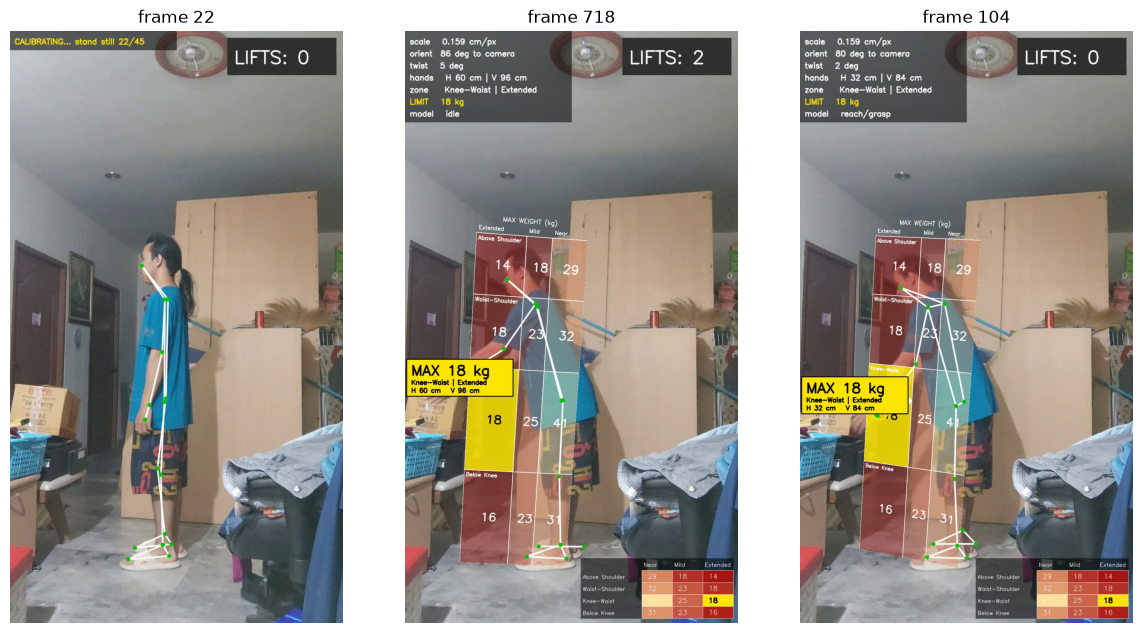

In [24]:
# ภาพนิ่ง 3 จังหวะ: ระหว่าง calibrate · เฟรมที่มือยื่นไกลที่สุด · เฟรมที่น้ำหนักที่ยอมรับได้ต่ำที่สุด
valid = results.dropna(subset=["limit_kg"])
frame_ids = [int(round(CALIB_SECONDS * FPS)) // 2,
             int(valid.loc[valid["H_cm"].idxmax(), "frame_number"]),
             int(valid.loc[valid["limit_kg"].idxmin(), "frame_number"])]
show_images([read_frame(FINAL_OUT, f) for f in frame_ids],
            [f"frame {f}" for f in frame_ids])

---
## ขั้นที่ ⑫ · สรุปผลรายรอบการยก

คำถามที่อาจารย์ทิ้งไว้ท้าย notebook demo คือ *"ถ้ารวมสองระบบเข้าด้วยกัน ควรรายงานน้ำหนักสูงสุด ณ เฟรมใดของการยกหนึ่งครั้ง"*

เราตอบว่า **เฟรมที่น้ำหนักที่ยอมรับได้ต่ำที่สุดในรอบนั้น** เพราะเป็นท่าที่เสี่ยงที่สุดของรอบ
ถ้าของที่ยกหนักเกินค่านี้ แปลว่ามีช่วงหนึ่งของการยกที่เกินเกณฑ์แล้ว แม้ท่าเริ่มต้นจะดูปลอดภัย

ตารางด้านล่างให้หนึ่งแถวต่อหนึ่งรอบการยก พร้อมท่าที่แย่ที่สุดและมุมบิดสูงสุดของรอบนั้น

In [25]:
def lift_report(results):
    # ⑫ หนึ่งแถวต่อหนึ่งรอบการยก (ใช้หมายเลขรอบจาก HeightRoundCounter)
    report = []
    for number in sorted(n for n in results["round"].unique() if n > 0):
        part = results[results["round"] == number]
        measured = part.dropna(subset=["limit_kg"])
        if measured.empty:
            continue
        worst = measured.loc[measured["limit_kg"].idxmin()]
        report.append({
            "lift": number,
            "start_s": round(part["time_s"].iloc[0], 2),
            "end_s": round(part["time_s"].iloc[-1], 2),
            "duration_s": round(part["time_s"].iloc[-1] - part["time_s"].iloc[0], 2),
            "V_start_cm": round(measured["V_cm"].iloc[0], 1),
            "V_end_cm": round(measured["V_cm"].iloc[-1], 1),
            "V_min_cm": round(measured["V_cm"].min(), 1),
            "V_max_cm": round(measured["V_cm"].max(), 1),
            "H_max_cm": round(measured["H_cm"].max(), 1),
            "twist_max_deg": round(part["twist_smooth_deg"].max(), 1),
            "shoulder_swing_deg": round(swing_range(part["shoulder_dir_deg"]), 1),
            "worst_frame": int(worst["frame_number"]),
            "worst_zone": f'{worst["zone"]} | {worst["reach_class"]}',
            "limit_kg": int(worst["limit_kg"]),
        })
    report = pd.DataFrame(report)
    if len(report):                                    # ⑦ เตือนบิดตัวเมื่อเข้าข้อใดข้อหนึ่ง
        report["twist_flag"] = ((report["twist_max_deg"] > TWIST_WARN_DEG)
                                | (report["shoulder_swing_deg"] > SWING_WARN_DEG))
    return report


lifts = lift_report(results)
lifts.to_csv(OUTPUT_DIR / f"{stem}_lifts.csv", index=False)
print(f"นับรอบการยกได้ {len(lifts)} รอบ")
display(lifts)
if len(lifts):
    worst = lifts.loc[lifts["limit_kg"].idxmin()]
    print(f"รอบที่เสี่ยงที่สุด: รอบ {worst['lift']} ที่เวลา {worst['start_s']}–{worst['end_s']} วินาที "
          f"· ท่าแย่สุดที่เฟรม {worst['worst_frame']} ({worst['worst_zone']}) "
          f"→ ยกได้ไม่เกิน {worst['limit_kg']} kg · บิดตัวสูงสุด {worst['twist_max_deg']}°")
    print(f"รอบที่เตือนบิดตัว: {int(lifts['twist_flag'].sum())} จาก {len(lifts)} รอบ "
          f"(ไหล่เทียบสะโพก > {TWIST_WARN_DEG:.0f}° หรือแนวไหล่แกว่ง > {SWING_WARN_DEG:.0f}°)")

นับรอบการยกได้ 8 รอบ


,lift,start_s,end_s,duration_s,V_start_cm,V_end_cm,V_min_cm,V_max_cm,H_max_cm,twist_max_deg,shoulder_swing_deg,worst_frame,worst_zone,limit_kg,twist_flag
0,1,4.70,6.77,2.07,96.9,89.5,89.5,106.6,40.4,6.1,19.7,141,Knee-Waist | Extended,18,False
1,2,11.90,15.20,3.30,96.4,89.5,89.5,103.1,41.8,5.4,19.2,357,Knee-Waist | Extended,18,False
2,3,20.13,24.97,4.83,97.5,89.8,89.8,129.5,60.0,6.7,14.4,604,Knee-Waist | Extended,18,False
3,4,28.03,31.37,3.33,96.2,89.7,89.7,109.9,55.0,6.3,17.1,841,Knee-Waist | Extended,18,False
4,5,36.77,40.13,3.37,97.2,89.7,89.7,106.7,40.5,5.3,19.5,1103,Knee-Waist | Extended,18,False
5,6,45.73,48.77,3.03,96.6,89.5,89.5,109.5,41.5,5.0,20.6,1372,Knee-Waist | Extended,18,False
6,7,53.97,57.17,3.20,96.7,89.6,89.6,111.1,43.7,4.5,10.2,1619,Knee-Waist | Extended,18,False
7,8,61.93,65.40,3.47,96.3,89.8,89.8,107.0,47.9,6.0,17.0,1858,Knee-Waist | Extended,18,False


รอบที่เสี่ยงที่สุด: รอบ 1 ที่เวลา 4.7–6.77 วินาที · ท่าแย่สุดที่เฟรม 141 (Knee-Waist | Extended) → ยกได้ไม่เกิน 18 kg · บิดตัวสูงสุด 6.1°
รอบที่เตือนบิดตัว: 0 จาก 8 รอบ (ไหล่เทียบสะโพก > 17° หรือแนวไหล่แกว่ง > 50°)


### 12.1 เส้นเวลา
แถบสีเขียว = รอบการยกที่นับได้ · เส้นประ = เกณฑ์ (เข่า/เอว/ไหล่ · 7″/12″ · มุมบิด 17°)

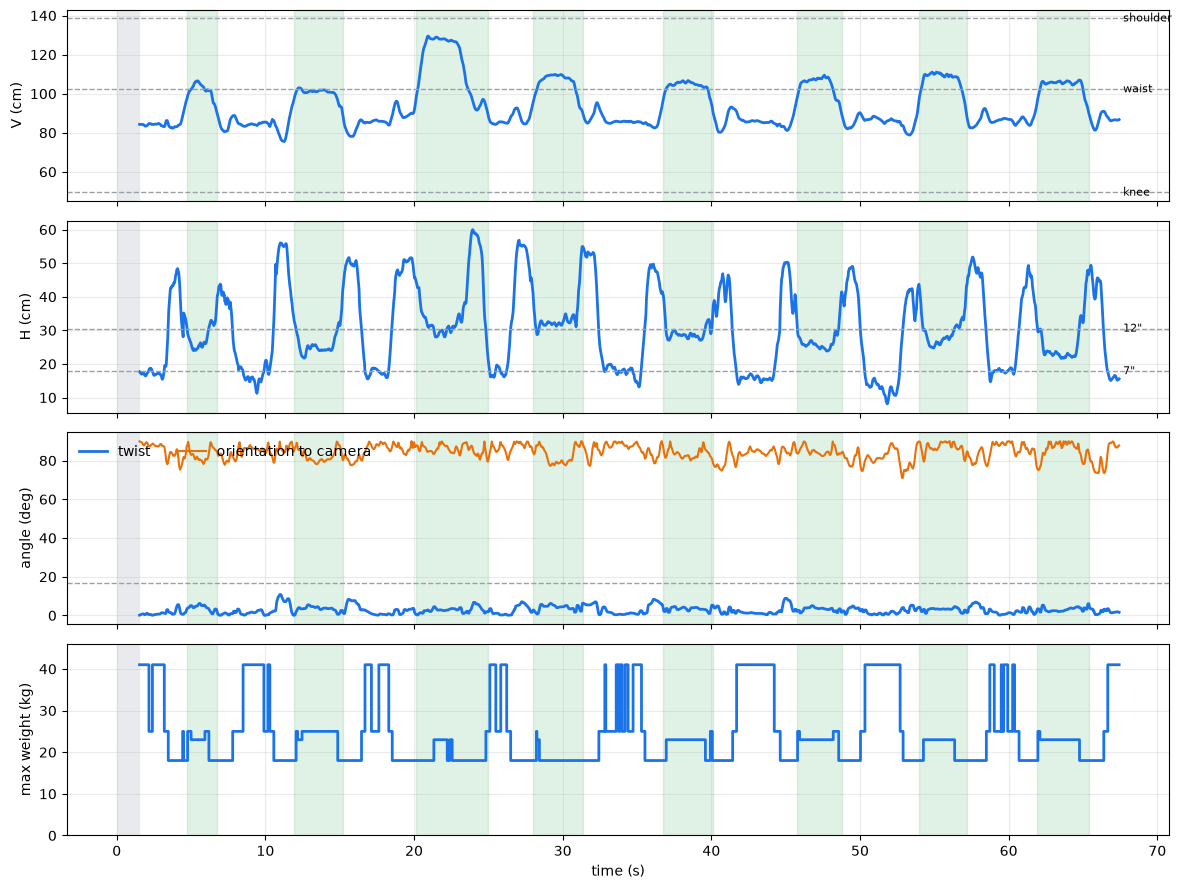

In [26]:
t = results["time_s"]
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
blue, grey = "#1a73e8", "#9aa0a6"

axes[0].plot(t, results["V_cm"], color=blue, lw=2)
for name in ["knee", "waist", "shoulder"]:
    axes[0].axhline(CALIB_RUN[name + "_cm"], color=grey, ls="--", lw=1)
    axes[0].text(t.iloc[-1], CALIB_RUN[name + "_cm"], " " + name, va="center", fontsize=8)
axes[0].set_ylabel("V (cm)")

axes[1].plot(t, results["H_cm"], color=blue, lw=2)
for cm, name in zip(REACH_LIMITS_CM, ['7"', '12"']):
    axes[1].axhline(cm, color=grey, ls="--", lw=1)
    axes[1].text(t.iloc[-1], cm, " " + name, va="center", fontsize=8)
axes[1].set_ylabel("H (cm)")

axes[2].plot(t, results["twist_smooth_deg"], color=blue, lw=2, label="twist")
axes[2].plot(t, results["orientation_deg"], color="#e8710a", lw=1.5, label="orientation to camera")
axes[2].axhline(TWIST_WARN_DEG, color=grey, ls="--", lw=1)
axes[2].set_ylabel("angle (deg)")
axes[2].legend(frameon=False, loc="upper left", ncol=2)

axes[3].step(t, results["limit_kg"], where="post", color=blue, lw=2)
axes[3].set_ylim(0, 46)
axes[3].set_ylabel("max weight (kg)")
axes[3].set_xlabel("time (s)")

for ax in axes:                                   # ช่วง calibrate + ช่วงที่กำลังยก
    ax.axvspan(0, CALIB_SECONDS, color="#e8eaed", zorder=0)
    for _, lift in lifts.iterrows():
        ax.axvspan(lift["start_s"], lift["end_s"], color="#34a853", alpha=0.15, zorder=0)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 12.2 เวลาที่มืออยู่ในแต่ละช่องของตาราง
ช่องที่ใช้เวลามากและน้ำหนักต่ำ คือจุดที่ควรปรับสถานีงานก่อน

In [27]:
seconds = valid.groupby(["zone", "reach_class"]).size() / FPS
zone_table = seconds.unstack("reach_class").reindex(index=ROW_NAMES, columns=COL_NAMES).fillna(0).round(2)
print("เวลาที่กึ่งกลางมืออยู่ในแต่ละช่อง (วินาที)")
display(zone_table)
print(f"น้ำหนักที่ยอมรับได้ต่ำสุดตลอดคลิป = {valid['limit_kg'].min():.0f} kg")
if len(lifts):
    print(f"มุมบิดตัวสูงสุดในรอบการยก = {lifts['twist_max_deg'].max():.0f}° (เกณฑ์ {TWIST_WARN_DEG:.0f}°) · "
          f"แนวไหล่แกว่งมากสุด = {lifts['shoulder_swing_deg'].max():.0f}° (เกณฑ์ {SWING_WARN_DEG:.0f}°)")
print(f"จำนวนรอบการยกที่นับได้ = {len(lifts)} รอบ")

เวลาที่กึ่งกลางมืออยู่ในแต่ละช่อง (วินาที)


reach_class,Near,Mild,Extended
zone,,,
Above Shoulder,0.00,0.00,0.00
Waist-Shoulder,0.00,12.13,5.83
Knee-Waist,12.43,12.30,23.23
Below Knee,0.00,0.00,0.00


น้ำหนักที่ยอมรับได้ต่ำสุดตลอดคลิป = 18 kg
มุมบิดตัวสูงสุดในรอบการยก = 7° (เกณฑ์ 17°) · แนวไหล่แกว่งมากสุด = 21° (เกณฑ์ 50°)
จำนวนรอบการยกที่นับได้ = 8 รอบ


---
## ขั้นที่ ⑬ · ตรวจความถูกต้องของค่าที่ calibrate (ใช้ตอนปรับค่าตั้งต้น)

ค่าที่ calibrate ได้เทียบกับ **สัดส่วนร่างกายมาตรฐาน** (Drillis & Contini) ซึ่งคิดเป็นสัดส่วนของส่วนสูง

| จุด | สัดส่วนมาตรฐาน |
|---|---|
| ความสูงเข่า | 0.285 |
| ความสูงไหล่ | 0.818 |
| ความสูงข้อมือขณะยืนปล่อยแขน | 0.485 |

> 🔑 สัดส่วนเหล่านี้ **ไม่ขึ้นกับส่วนสูงที่กรอก** เพราะทุกค่าสเกลเป็นเส้นตรงตาม `SUBJECT_HEIGHT_CM`
> จึงใช้ตรวจว่าการ calibrate เพี้ยนหรือไม่ได้ แม้ยังไม่รู้ส่วนสูงจริง
> ส่วนค่าที่ **ขึ้นกับส่วนสูงจริง** คือ H และ V เป็นเซนติเมตร ซึ่งมีผลกับการแบ่งคอลัมน์ Near/Mild/Extended

In [28]:
REFERENCE = {"knee": 0.285, "shoulder": 0.818, "wrist": 0.485}
n_calib = int(round(CALIB_SECONDS * FPS))
still = valid[valid["frame_number"].between(n_calib + 1, n_calib + 15)]

check = pd.DataFrame([
    {"ค่า": "ความสูงเข่า", "วัดได้ (ซม.)": CALIB_RUN["knee_cm"],
     "สัดส่วนที่วัดได้": CALIB_RUN["knee_cm"] / SUBJECT_HEIGHT_CM, "สัดส่วนมาตรฐาน": REFERENCE["knee"]},
    {"ค่า": "ความสูงไหล่", "วัดได้ (ซม.)": CALIB_RUN["shoulder_cm"],
     "สัดส่วนที่วัดได้": CALIB_RUN["shoulder_cm"] / SUBJECT_HEIGHT_CM, "สัดส่วนมาตรฐาน": REFERENCE["shoulder"]},
    {"ค่า": "ความสูงมือขณะยืนนิ่ง", "วัดได้ (ซม.)": still["V_cm"].median(),
     "สัดส่วนที่วัดได้": still["V_cm"].median() / SUBJECT_HEIGHT_CM, "สัดส่วนมาตรฐาน": REFERENCE["wrist"]},
])
check["ต่างจากมาตรฐาน"] = (check["สัดส่วนที่วัดได้"] - check["สัดส่วนมาตรฐาน"]).round(3)
display(check.round(3))
print(f"ระยะกล้อง: จาก cm/px = {CALIB_RUN['camera_dist_cm']:.0f} ซม.")
print(f"H ขณะยืนนิ่ง = {still['H_cm'].median():.1f} ซม. (ยืนปล่อยแขนควรได้ประมาณ 10–20 ซม.)")
print(f"มุมหันเทียบกล้อง (มัธยฐาน) = {results['orientation_deg'].median():.0f}° "
      f"(ถ่ายด้านข้างตามโปรโตคอลควรเข้าใกล้ 90°)")

,ค่า,วัดได้ (ซม.),สัดส่วนที่วัดได้,สัดส่วนมาตรฐาน,ต่างจากมาตรฐาน
0,ความสูงเข่า,49.441,0.296,0.285,0.011
1,ความสูงไหล่,138.587,0.830,0.818,0.012
2,ความสูงมือขณะยืนนิ่ง,84.221,0.504,0.485,0.019


ระยะกล้อง: จาก cm/px = 218 ซม.
H ขณะยืนนิ่ง = 17.2 ซม. (ยืนปล่อยแขนควรได้ประมาณ 10–20 ซม.)
มุมหันเทียบกล้อง (มัธยฐาน) = 85° (ถ่ายด้านข้างตามโปรโตคอลควรเข้าใกล้ 90°)


---
## ขั้นที่ ⑭ · ผลการปรับค่าตั้งต้น การทดสอบกับคลิปยกหลายรอบ และคลิปของกลุ่มอื่น

ข้อมูลที่ใช้: **20 คลิปเดิมของกลุ่ม** (ผู้ยก 4 คน · คำตอบมาจากรหัสในชื่อไฟล์) และ **2 คลิปยกหลายรอบที่ถ่ายใหม่**
(ผู้ยกสูง 167 ซม. · ถ่ายด้านข้าง · นับรอบด้วยตาได้ 8 และ 7 รอบ ตรงกับจำนวนลูกคลื่นในกราฟความสูงมือ)
ทดลองโดยสกัด keypoint ของทุกคลิปเก็บไว้ครั้งเดียว แล้วรันขั้น ③–⑫ ซ้ำด้วยค่าต่าง ๆ

### 14.1 ตัวนับรอบ: เทียบสามแบบ (ถูกกี่คลิปจาก 22)
| ตัวนับ | ถูก | คลิปยกปกติ (จริง 8) | คลิปยกเร็ว (จริง 7) | คลิปที่ไม่มีการยก 4 คลิป |
|---|---|---|---|---|
| ป้ายของโมเดลอย่างเดียว (แบบ demo ปรับค่าแล้ว) | 18 | 10 | 4 | ถูก 3 |
| ความสูงมืออย่างเดียว | 20 | 8 | 7 | ถูก 2 (นับการเดินและการก้มเป็นการยก) |
| **ความสูงมือ + โมเดลยืนยัน (ที่ใช้)** | **22** | **8** | **7** | **ถูก 4** |

ค่าตั้งต้นของ demo (นับเฉพาะ `lift` ต่อเนื่อง 6 เฟรม) นับถูกแค่ 10 จาก 20 คลิปเดิม

### 14.2 ค่าอื่นที่ปรับ
| ค่า | ค่าตั้งต้นของ demo | ค่าของกลุ่ม | ผล |
|---|---|---|---|
| การเตือนบิดตัว | ไหล่เทียบสะโพก > 45° | รายรอบ: ไหล่เทียบสะโพก > 17° **หรือ** แนวไหล่แกว่งเทียบพื้น > 50° | จับคลิป T1 ได้ 1 → **11 จาก 13** (ดู 14.5) |
| `MAX_REACH_FRACTION` | ไม่มี | 0.50 | ตัดเฟรมที่ H เกินช่วงแขน (เจอใน 3 คลิป สูงสุด 127 ซม.) |
| ตาราง 2 มิติมุมจอ | ไม่มี | เพิ่ม | อ่านค่าได้แม้ตารางในฉากหันสันเข้ากล้อง |

### 14.3 ค่าที่ทดลองแล้ว **ไม่ต้องปรับ**
| ค่า | สิ่งที่ลอง | สิ่งที่พบ |
|---|---|---|
| `CAMERA_FOV_DEG` | 50, 60, 70, 80, 90, 110 | สัดส่วนเข่า/ไหล่/ข้อมือแทบไม่เปลี่ยน ค่า FOV เปลี่ยนแค่ระยะกล้องที่คำนวณได้ ที่ 70° คลิปใหม่คำนวณได้ 2.2 ม. อยู่ในช่วง 2–3 ม. ที่กลุ่มประมาณไว้ จึงคงค่าเดิม |
| การแบ่งแถวตามความสูงมือ | เทียบกับรหัสโซนในชื่อไฟล์ | มือผ่านโซนต้นทาง **16 จาก 16** คลิป และโซนปลายทาง **14 จาก 16** คลิป |

### 14.4 ตรวจกับสัดส่วนร่างกายมาตรฐาน
| จุด | 20 คลิปเดิม (มัธยฐาน) | คลิปใหม่ (ส่วนสูงจริง 167 ซม.) | มาตรฐาน |
|---|---|---|---|
| ความสูงเข่า / ส่วนสูง | 0.267 | 0.29 (49 ซม.) | 0.285 |
| ความสูงไหล่ / ส่วนสูง | 0.799 | 0.83 (139 ซม.) | 0.818 |
| ความสูงมือขณะยืนนิ่ง / ส่วนสูง | 0.491 | 0.50 (84 ซม.) | 0.485 |

คลิปใหม่ถ่ายด้านข้างตรงโปรโตคอล (มุมหันมัธยฐาน 85°) สัดส่วนที่วัดได้จึงใกล้มาตรฐานกว่าคลิปเดิม

### 14.5 ทดสอบกับคลิปของกลุ่มอื่น
คลิปที่มีวิดีโอใน Drive รวม: **G01 20 คลิป** (ผู้ยก 4 คน) และ **G20 5 คลิป** (ผู้ยก 1 คน) ใช้ส่วนสูงสมมติ 170 ซม.
ค่าของตัวนับและการแบ่งโซนไม่เคยปรับจากคลิปเหล่านี้ ส่วนโมเดลเคยเห็น 5 คลิป (G01 S02 อยู่ในชุด train) · ผลรายคลิปอยู่ใน `tuning/batch_eval_other.csv`

| สิ่งที่ตรวจ | ผล |
|---|---|
| จำนวนรอบ | ถูก **21 จาก 25** คลิป |
| มือผ่านโซนต้นทาง / ปลายทาง ตามรหัส | **20 จาก 20** / **18 จาก 20** |
| เกณฑ์มุมบิดเดิม 27° จับคลิป T1 | **1 จาก 9** (วัดได้ 9–31°) → ต้องเปลี่ยนวิธีวัด ดูด้านล่าง |

คลิปที่นับรอบผิด 4 คลิป
| คลิป | จริง → นับได้ | สาเหตุ |
|---|---|---|
| `G01_S01_NEG-WALK` | 0 → 1 | ความสูงมือที่วัดได้เปลี่ยนจาก 105 เป็น 153 ซม. ขณะเดิน และโมเดลตอบ `lower/place` |
| `G01_S05_NEG-TWIST` | 0 → 1 | ยกมือขึ้นขณะบิดตัว (V 86 → 113 ซม.) และโมเดลตอบว่ามีของในมือบางช่วง |
| `G01_S04_BK-WS_T1` | 1 → 2 | ก้มหยิบจากพื้นแล้วยกขึ้นชั้น มือผ่านระดับยืนนิ่งกลางรอบนานพอจนถูกตัดเป็นสองรอบ |
| `G01_S05_WS-AS_T1` | 1 → 0 | ความสูงมือเห็นชัด (90 → 168 ซม.) แต่โมเดลตอบว่ามีของในมือเพียง 6% ของคลิป ต่ำกว่าเกณฑ์ 20% |

**การเตือนบิดตัว: จากเกณฑ์เดียวเป็นกฎสองข้อ**

เกณฑ์ 27° ที่ได้จากคลิปของกลุ่มเราใช้กับกลุ่มอื่นไม่ได้ เพราะผู้ยกของกลุ่มอื่นบิดแบบหมุนทั้งลำตัว สะโพกหมุนตามไหล่
มุมไหล่เทียบสะโพกจึงต่ำ (9–18°) แม้จะบิดจริง เราลองตัววัด 9 แบบกับ 36 คลิปที่มีการยก (`tuning/twist_measures.csv`)
แบบที่แยกคลิปของกลุ่มอื่นได้ดีที่สุดคือ **แนวไหล่แกว่งเทียบกับพื้นภายในรอบ** จึงใช้คู่กับมุมไหล่เทียบสะโพก

| กฎ | กลุ่มเรา (16) | กลุ่มอื่น (20) | รวม (36) | จับ T1 | เตือนผิดใน T0 |
|---|---|---|---|---|---|
| demo: ไหล่เทียบสะโพก > 45° | 13 | 11 | 24 | 1 จาก 13 | 0 จาก 23 |
| ไหล่เทียบสะโพก > 27° | 15 | 12 | 27 | 4 จาก 13 | 0 จาก 23 |
| **ไหล่เทียบสะโพก > 17° หรือ แนวไหล่แกว่ง > 50° (ที่ใช้)** | 12 | 17 | **29** | **11 จาก 13** | 5 จาก 23 |

- กฎใหม่ถูกเพิ่มแค่ 2 คลิปเมื่อนับรวม สิ่งที่เปลี่ยนจริงคือ **จับการบิดตัวได้เกือบหมด แลกกับการเตือนผิด 5 คลิป** ซึ่งเหมาะกับงานคัดกรองมากกว่าการปล่อยผ่าน
- คะแนนของกลุ่มเราลดจาก 15 เป็น 12 เพราะเตือนผิด 4 คลิป โดย 3 คลิปถ่ายเกือบหน้าตรง (มุมหัน 7–31°) ซึ่งทิศของแนวไหล่วัดได้ไม่นิ่ง
- คลิป T1 ที่ยังพลาด 2 คลิป: `G20_S05_WS-AS` (วัดได้ 15° และ 27°) และ `G01_S05_WS-AS` ที่ตัวนับไม่พบรอบจึงไม่มีการตรวจ
- ค่า 17° และ 50° ปรับจาก 35 คลิปที่นับรอบได้ชุดนี้เอง เมื่อปรับโดยกันผู้ยกออกทีละคน (9 คน) ได้ถูก 27 จาก 35
- ค่า 17° อยู่ชิดขอบ: คลิป T0 วัดได้สูงสุด 17.3° ส่วนคลิป T1 ที่ต้องอาศัยข้อนี้วัดได้ 17.8° ทั้งสองคลิป
- การเตือนคิดเมื่อจบรอบ ตัวเลขบนวิดีโอขณะเล่นแสดงเฉพาะมุมไหล่เทียบสะโพก

### 14.6 สิ่งที่ยังไม่ดี
- **ตัวนับพลาด 4 จาก 25 คลิปของกลุ่มอื่น** (ตาราง 14.5) ส่วน 22 จาก 22 เป็นคลิปชุดที่ใช้ปรับค่าเอง
- **การเตือนบิดตัวยังเตือนผิด 5 จาก 23 คลิปที่ไม่บิด** และค่าปรับจากคลิปชุดเดียวกับที่ใช้วัดผล ยังไม่มีคลิปที่ไม่เคยเห็นมายืนยัน
- **ป้ายของโมเดลยังอ่อนในคลิปยกเร็ว** บางรอบโมเดลตอบว่ามีของในมือเพียง 26–39% ของรอบ ใกล้เกณฑ์ 20% ที่ตั้งไว้
- **ตัวนับรู้ผลเมื่อจบรอบ** และถ้ามือไม่กลับมาใกล้ระดับยืนนิ่งระหว่างสองรอบ จะถูกนับรวมเป็นรอบเดียว
- **15 จาก 20 คลิปเดิมยังใช้ส่วนสูงสมมติ 170 ซม.** (5 คลิปของ S03 ใช้ส่วนสูงจริง 167 ซม. ผลรวมไม่เปลี่ยน) และมุมกล้องเอียง (มุมหันมัธยฐาน S03 31–52° · S04 7–36°)
- **ไม่ได้แปะเทปที่ 18 และ 30 ซม.** จึงยังไม่ได้ตรวจความแม่นของ H เป็นเซนติเมตรกับของจริง

---
## 🧭 สรุป

| ขั้น | ฟังก์ชันหลัก | ได้อะไร |
|---|---|---|
| ①–④ | `open_video` · `extract_keypoints` · `PoseSmoother` · `draw_skeleton` | keypoint ที่นิ่งแล้ว |
| ⑤ | `calibrate` · `solve_camera_pose` · `to_camera_3d` · `body_frame` | ซม./พิกเซล · พิกัด 3 มิติ · ระดับเข่า/เอว/ไหล่ |
| ⑥ ⑦ | `orientation_angle` · `twist_from_baseline` | มุมหันกล้อง · **มุมบิดตัว** |
| ⑧ | `measure_hands` · `draw_weight_table` · `draw_mini_table` | **H / V แบบ NIOSH** · ตารางน้ำหนัก 3×4 |
| ⑨ ⑩ | `FeatureStream` · `predict_window` · `MajorityVote` · `HeightRoundCounter` | กิจกรรมรายเฟรม · **จำนวนรอบการยก** |
| ⑪ ⑫ | `run_pipeline` · `lift_report` | วิดีโอ + CSV รายเฟรม + **ตารางสรุปรายรอบ** |

### ข้อจำกัดที่ต้องบอกผู้ใช้
- ความลึกมาจากโครงร่าง 3 มิติของ MediaPipe กับค่า FOV ที่สมมติ จึงยังไม่ใช่การวัดจริง ควรตรวจกับกล่องที่ระยะ 7″/12″ ก่อนใช้งานจริง
- ตารางน้ำหนักเป็นเกณฑ์ **ท่าทาง** ไม่ได้บอกว่าของที่ยกหนักเท่าไร ระบบจึงบอกได้แค่ "ท่านี้ยกได้ไม่เกินกี่กิโล"
- โมเดลกิจกรรมมี macro-F1 ประมาณ 0.43 บนชุด test ตัวนับรอบจึงใช้ความสูงมือเป็นหลัก และใช้โมเดลแค่ยืนยันว่ามีของในมือ
- ต้องยืนนิ่งช่วงต้นคลิปเพื่อ calibrate ถ้าขยับระหว่างนั้นค่าสเกลจะเพี้ยนทั้งคลิป